# Deep Armocromia — E13: Fusion DINOv3 ViT-B + Lab per Region + Logit Hierarkis

Lanjutan E12. Fokus tunggal: **akurasi sub-season (12 kelas)**, target ≥ 50% di holdout. Undertone tidak dilaporkan; sinyal undertone dan Lab hanya dipakai **di dalam model** untuk menaikkan akurasi sub-season.

| Temuan di E12 | Perubahan di E13 |
|---|---|
| Nama file generik (`images (12).png`) dianggap satu orang → satu grup 396 foto, fold timpang (1098 vs ~650) | Nama generik dibuang dari pengelompokan (`GENERIC_NAMES`) |
| Identitas CelebA tidak ada | Opsional: identitas asli dari `CelebA-HQ-to-CelebA-mapping.txt` + `identity_CelebA.txt` bila di-attach, dengan uji kecocokan otomatis |
| Holdout kecil (290), CI ±5 poin | `HOLDOUT_FRAC = 0.20` |
| Fitur Lab hanya masuk lewat HGB terpisah | **Fusion**: fitur Lab per region masuk langsung ke jaringan fine-tuned (cabang MLP) |
| Head 12 kelas berdiri sendiri; head season/karakteristik/undertone hanya loss tambahan | **Logit hierarkis**: logit 12 kelas = logit langsung + logit season + logit karakteristik + logit undertone dari kelas tersebut |
| Label smoothing seragam | **Label smoothing hierarkis**: massa smoothing diarahkan ke kelas tetangga (season / karakteristik sama) |
| Backbone ViT-S/16 | Fine-tuning **ViT-B/16** (embedding frozen tetap ViT-S agar ambang near-duplicate E12 tetap berlaku) |
| Bobot akhir = bobot epoch terakhir | **EMA bobot** untuk evaluasi dan prediksi |
| XGBoost stacking tidak lebih baik dari ensemble | Dihapus |
| Loss validasi tidak dicatat | **Loss train dan loss validasi** dicetak tiap epoch dan diplot per fold; kurva loss HGB dan tabel log-loss LR juga ditampilkan |

**Syarat Kaggle:** GPU T4, Internet ON, dataset Deep Armocromia ter-attach, Secrets `DEEP_ARMO_PASSWORD` dan `HF_TOKEN` aktif (akun HF sudah disetujui untuk `dinov3-vits16` dan `dinov3-vitb16`).
Opsional: attach dataset yang berisi `CelebA-HQ-to-CelebA-mapping.txt` (CelebAMask-HQ) dan `identity_CelebA.txt` (CelebA). Cukup file teksnya; jangan attach folder gambar CelebA penuh karena pencarian file jadi lambat.

**Cara pakai:** jalankan dulu `SMOKE_TEST = True` (angkanya tidak bermakna), lalu `SMOKE_TEST = False` dan *Run All*. Perkiraan waktu run penuh di T4: ±2–2,5 jam.

**Aturan evaluasi:** semua keputusan diambil dari OOF subset CelebA. Holdout dan official test baru dibuka di bagian 9. Angka **holdout** adalah angka yang dilaporkan.

In [1]:
# ============================================================
# 0. CONFIG
# ============================================================
EXPERIMENT_ID = "E13_FUSION_LAB_HIER"
SEED = 42
NUM_CLASSES = 12
NUM_SEASONS = 4
SMOKE_TEST = False         # True = uji cepat alur (subset kecil, 1 epoch). Set False untuk run sebenarnya.
TARGET_ACC = 0.50          # target akurasi sub-season di holdout

# --- Secrets ---
DATA_PASSWORD_SECRET_NAME = "DEEP_ARMO_PASSWORD"
HF_TOKEN_SECRET_NAME = "HF_TOKEN"

# --- Backbone ---
FROZEN_HF_ID = "facebook/dinov3-vits16-pretrain-lvd1689m"   # embedding frozen (emb_lr + near-duplicate), sama dengan E12
FT_HF_ID = "facebook/dinov3-vitb16-pretrain-lvd1689m"       # backbone fine-tuning. Kembali ke vits16 bila kehabisan waktu/memori.
EMB_IMG_SIZE = 224
EXTRA_MEAN_LAYERS = [4, 8]

# --- Face parsing ---
PARSER_HF_ID = "jonathandinu/face-parsing"
PARSE_SIZE = 512
CACHE_SIZE = 256
MASK_THRESH = 8 / 255
PARSE_BATCH = 16
USE_BINARY_MASK = True

# --- Grup, holdout, CV ---
N_FOLDS = 5
DUP_THR = 0.90
HOLDOUT_FRAC = 0.20
GENERIC_NAMES = {"images", "image", "img", "download", "downloads", "unnamed", "untitled", "photo", "foto",
                 "picture", "pic", "screenshot", "file", "immagine", "senza titolo"}
USE_CELEBA_IDENTITY = True
IDENTITY_MIN_AGREEMENT = 0.30   # identitas CelebA dipakai hanya bila >= 30% pasangan near-duplicate CelebA ber-ID sama

# --- Komponen klasik ---
C_GRID = [3e-4, 1e-3, 3e-3]

# --- Fine-tuning fusion ---
FT_IMG_SIZE = 224
FT_EPOCHS = 15
FT_BATCH = 32
FT_LR_HEAD = 1e-3
FT_LR_BACKBONE = 2e-5
FT_LLRD = 0.80
FT_WD = 0.05
FT_WARMUP_EPOCHS = 1
FT_LABEL_SMOOTH = 0.1
FT_HIER_SMOOTH = True       # smoothing diarahkan ke kelas tetangga
FT_HIER_LOGITS = True       # logit 12 kelas ditambah logit season/karakteristik/undertone
FT_USE_COLOR = True         # cabang fitur Lab per region di dalam jaringan
FT_COLOR_HIDDEN = 256
FT_COLOR_DROP = 0.10        # peluang cabang warna dimatikan per sampel saat training (agar tidak bergantung penuh)
FT_DROPOUT = 0.2
FT_AUX_W = 0.3
FT_EMA = 0.998              # 0 = tanpa EMA
FT_SEEDS = [42, 7]
FT_NUM_WORKERS = 2
FT_SAVE_CKPT = True

# --- Ensemble & evaluasi ---
ENS_STEP = 0.1
N_BOOT = 2000
ECE_BINS = 15

RECOMPUTE = False
EXPECTED_ROWS = (4920, 4008, 912)

REFERENCE = {
    "E10 (frozen DINOv3 + LR) test": {"acc": 0.2939, "macro_f1": 0.2618, "top3": 0.6436},
    "FaRL16_E6 test":                {"acc": 0.3246, "macro_f1": 0.2947, "top3": 0.6579},
    "E12 ensemble test":             {"acc": 0.3542, "macro_f1": 0.3232, "top3": 0.7193},
    "E12 ensemble holdout":          {"acc": 0.2862, "macro_f1": 0.2729, "top3": 0.6897},
}

if SMOKE_TEST:
    FT_EPOCHS, N_FOLDS, C_GRID, N_BOOT, FT_SEEDS = 1, 3, [1e-3], 200, [42]
LOG_TO_REGISTRY = not SMOKE_TEST

from pathlib import Path
RESULT_DIR = Path("/kaggle/working/E13" + ("_smoke" if SMOKE_TEST else ""))
RESULT_DIR.mkdir(parents=True, exist_ok=True)
print("Experiment:", EXPERIMENT_ID, "| SMOKE_TEST =", SMOKE_TEST)
print("Frozen    :", FROZEN_HF_ID)
print("Fine-tune :", FT_HF_ID)
print("Hasil     :", RESULT_DIR)

Experiment: E13_FUSION_LAB_HIER | SMOKE_TEST = False
Frozen    : facebook/dinov3-vits16-pretrain-lvd1689m
Fine-tune : facebook/dinov3-vitb16-pretrain-lvd1689m
Hasil     : /kaggle/working/E13


In [2]:
# ============================================================
# 1. IMPORTS
# ============================================================
import os, re, gc, json, time, math, copy, shutil, hashlib, itertools, subprocess, warnings, random

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image, ImageOps
from joblib import dump
from tqdm.auto import tqdm

from scipy.optimize import minimize_scalar
from scipy.sparse import coo_matrix
from scipy.sparse.csgraph import connected_components
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.exceptions import ConvergenceWarning
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import precision_recall_fscore_support, confusion_matrix
from sklearn.metrics import f1_score as sk_f1_score
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

try:
    from IPython.display import display
except ImportError:
    display = print

warnings.filterwarnings("ignore", category=ConvergenceWarning)
pd.set_option("display.max_columns", None)
pd.set_option("display.width", 220)
random.seed(SEED); np.random.seed(SEED)
print("numpy", np.__version__, "| pandas", pd.__version__)

numpy 2.1.3 | pandas 2.3.3


## 2. Dataset dan anotasi

In [3]:
# ============================================================
# 2.1 DETEKSI DATASET
# ============================================================
KAGGLE_INPUT = Path("/kaggle/input")
WORK_PREPARED_ROOT = Path("/kaggle/working/deep_armocromia_prepared")

prepared, source = [], []
for ann in KAGGLE_INPUT.rglob("annotations.csv"):
    root = ann.parent
    if (root / "RGB-M").is_dir():
        prepared.append((root, ann))
    if (root / "RGB-M.zip").is_file():
        source.append((root, ann, root / "RGB-M.zip"))

if prepared:
    MODE = "PREPARED_INPUT"
    DATA_ROOT, ANNOTATION_PATH = prepared[0]
elif source:
    MODE = "ENCRYPTED_SOURCE"
    _, ANNOTATION_PATH, _ = source[0]
    DATA_ROOT = WORK_PREPARED_ROOT
else:
    raise FileNotFoundError("annotations.csv + RGB-M/ atau RGB-M.zip tidak ditemukan di /kaggle/input.")
print("MODE:", MODE, "| ANNOTATION:", ANNOTATION_PATH)

MODE: ENCRYPTED_SOURCE | ANNOTATION: /kaggle/input/datasets/fatihitsbatulhaq/deep-armocromia/Deep Armocromia/release/annotations.csv


In [4]:
# ============================================================
# 2.2 LOAD ANNOTATIONS
# ============================================================
df = pd.read_csv(ANNOTATION_PATH)
SEASON_COL, SUBCLASS_COL, PARTITION_COL, MASKED_PATH_COL = "class", "sub_class", "partition", "path_rgb_masked"
missing = [c for c in [SEASON_COL, SUBCLASS_COL, PARTITION_COL, MASKED_PATH_COL, "celeba"] if c not in df.columns]
assert not missing, f"Missing columns: {missing}"

for col in [SEASON_COL, SUBCLASS_COL, PARTITION_COL]:
    df[col] = df[col].astype(str).str.strip().str.lower()
if df["celeba"].dtype != bool:
    mapped = df["celeba"].astype(str).str.strip().str.lower().map({"true": True, "1": True, "false": False, "0": False})
    assert mapped.notna().all(), "Kolom celeba punya nilai tak dikenal."
    df["celeba"] = mapped.astype(bool)
df["joint_label"] = df[SEASON_COL] + "_" + df[SUBCLASS_COL]

if EXPECTED_ROWS:
    assert len(df) == EXPECTED_ROWS[0], f"Jumlah baris {len(df)} != {EXPECTED_ROWS[0]}"
assert df[SEASON_COL].nunique() == NUM_SEASONS and df["joint_label"].nunique() == NUM_CLASSES

if SMOKE_TEST:
    tr_s = df[df[PARTITION_COL] == "train"].groupby("joint_label").sample(n=30, random_state=SEED)
    te_s = df[df[PARTITION_COL] == "test"].groupby("joint_label").sample(n=10, random_state=SEED)
    df = pd.concat([tr_s, te_s]).sort_index()
    print("SMOKE_TEST: memakai subset", len(df), "gambar.")

df = df.reset_index(drop=True)
display(pd.crosstab(df[PARTITION_COL], df["celeba"]))
MASK_COL = "path_mask" if "path_mask" in df.columns else None

celeba,False,True
partition,,
test,0,912
train,1939,2069


In [5]:
# ============================================================
# 2.3 SIAPKAN FOLDER GAMBAR: RGB-M (wajib) dan mask biner (opsional)
# ============================================================
SRC_ROOT = ANNOTATION_PATH.parent
WORK_PREPARED_ROOT.mkdir(parents=True, exist_ok=True)
_PW = {}

def get_password():
    if "v" not in _PW:
        from kaggle_secrets import UserSecretsClient
        try:
            _PW["v"] = UserSecretsClient().get_secret(DATA_PASSWORD_SECRET_NAME)
        except Exception as e:
            raise RuntimeError(f"Secret '{DATA_PASSWORD_SECRET_NAME}' belum tersedia / belum di-enable.") from e
        assert _PW["v"]
    return _PW["v"]

def norm_rel(rel):
    return Path(str(rel).replace("\\", "/").strip().lstrip("/"))

def resolve_in(rel, top):
    p = norm_rel(rel)
    for root in (SRC_ROOT, WORK_PREPARED_ROOT):
        for c in (root / p, root / top / p):
            if c.is_file():
                return c
    return None

def resolve_column(col):
    top = norm_rel(df[col].iloc[0]).parts[0]
    return df[col].apply(lambda r: resolve_in(r, top)), top

def extract_zip(zip_path):
    pw = get_password()
    unzip_path = shutil.which("unzip")
    if unzip_path:
        r = subprocess.run([unzip_path, "-n", "-P", pw, str(zip_path), "-d", str(WORK_PREPARED_ROOT)],
                           stdout=subprocess.DEVNULL, stderr=subprocess.PIPE, text=True)
        if r.returncode not in (0, 1):
            raise RuntimeError(r.stderr[-3000:])
    else:
        import zipfile
        with zipfile.ZipFile(zip_path, "r") as z:
            z.extractall(WORK_PREPARED_ROOT, pwd=pw.encode("utf-8"))

def ensure_column(col, required):
    paths, top = resolve_column(col)
    if not paths.notna().all():
        zips = [SRC_ROOT / f"{top}.zip"] + sorted(KAGGLE_INPUT.rglob(f"{top}.zip"))
        zips = [z for z in zips if z.is_file()]
        if zips:
            try:
                print(f"Mengekstrak {zips[0].name} ...")
                extract_zip(zips[0])
                paths, _ = resolve_column(col)
            except Exception as e:
                if required:
                    raise
                print(f"CATATAN: gagal mengekstrak {zips[0].name}: {str(e)[:300]}")
    if paths.notna().all():
        return paths
    msg = f"Kolom '{col}': {int(paths.isna().sum())} dari {len(paths)} file tidak ditemukan."
    if required:
        raise FileNotFoundError(msg)
    print("CATATAN:", msg, "-> fitur ini dimatikan.")
    return None

df["resolved_path"] = ensure_column(MASKED_PATH_COL, required=True)
df["mask_path"] = None
if USE_BINARY_MASK and MASK_COL:
    _r = ensure_column(MASK_COL, required=False)
    if _r is not None:
        df["mask_path"] = _r
_PW.clear()
HAS_MASK = bool(df["mask_path"].notna().all())
print(f"RGB-M: {len(df)} file | mask biner: {'ADA' if HAS_MASK else 'tidak dipakai'}")

Mengekstrak RGB-M.zip ...
Mengekstrak BM.zip ...
RGB-M: 4920 file | mask biner: ADA


In [6]:
# ============================================================
# 2.4 PATH, MD5, LABEL, SPLIT RESMI
# ============================================================
def md5_file(path, chunk=1024 * 1024):
    h = hashlib.md5()
    with open(path, "rb") as f:
        for b in iter(lambda: f.read(chunk), b""):
            h.update(b)
    return h.hexdigest()

df["md5"] = df["resolved_path"].apply(md5_file)
assert (df.groupby("md5")[PARTITION_COL].nunique() > 1).sum() == 0, "Ada gambar identik di train dan test."
md5_all = df["md5"].to_numpy().astype(str)
N_ALL = len(df)

class_names = sorted(df["joint_label"].unique().tolist())
class2idx = {n: i for i, n in enumerate(class_names)}
idx2class = {i: n for n, i in class2idx.items()}
season_names = sorted(df[SEASON_COL].unique().tolist())
char_names = sorted(df[SUBCLASS_COL].unique().tolist())
season2idx = {n: i for i, n in enumerate(season_names)}
char2idx = {n: i for i, n in enumerate(char_names)}
WARM_SEASONS = {"autunno", "primavera"}

season_of = np.array([season2idx[n.split("_", 1)[0]] for n in class_names])
char_of = np.array([char2idx[n.split("_", 1)[1]] for n in class_names])
warm_of = np.array([int(n.split("_", 1)[0] in WARM_SEASONS) for n in class_names])
NUM_CHARS = len(char_names)

df["target"] = df["joint_label"].map(class2idx).astype(int)
ALL_Y = {"y12": df["target"].to_numpy(), "yS": season_of[df["target"].to_numpy()],
         "yC": char_of[df["target"].to_numpy()], "yU": warm_of[df["target"].to_numpy()]}

is_train = (df[PARTITION_COL] == "train").to_numpy()
train_rows, test_rows = np.where(is_train)[0], np.where(~is_train)[0]
if EXPECTED_ROWS and not SMOKE_TEST:
    assert len(train_rows) == EXPECTED_ROWS[1] and len(test_rows) == EXPECTED_ROWS[2]
yte = ALL_Y["y12"][test_rows]
print("Kelas        :", class_names)
print("Train / test :", len(train_rows), "/", len(test_rows))

Kelas        : ['autunno_deep', 'autunno_soft', 'autunno_warm', 'estate_cool', 'estate_light', 'estate_soft', 'inverno_bright', 'inverno_cool', 'inverno_deep', 'primavera_bright', 'primavera_light', 'primavera_warm']
Train / test : 4008 / 912


## 3. Face parsing dan fitur Lab per region

Statistik L\*a\*b\* dihitung terpisah untuk kulit, rambut, mata, bibir, dan alis: median, kuartil (p25/p75) tiap kanal, sebaran, chroma, hue, ditambah kontras antar region. Dibanding E12, kuartil a\* dan b\* ditambahkan karena undertone lebih terlihat dari sebaran a\*/b\* daripada dari mediannya saja. Fitur ini dipakai di dua tempat: komponen `color_hgb` dan cabang warna di dalam jaringan fusion.

In [7]:
# ============================================================
# 3.1 FUNGSI WARNA
# ============================================================
def rgb2lab_np(rgb):
    rgb = np.asarray(rgb, dtype=np.float64)
    lin = np.where(rgb > 0.04045, ((rgb + 0.055) / 1.055) ** 2.4, rgb / 12.92)
    M = np.array([[0.4124564, 0.3575761, 0.1804375],
                  [0.2126729, 0.7151522, 0.0721750],
                  [0.0193339, 0.1191920, 0.9503041]])
    xyz = (lin @ M.T) / np.array([0.95047, 1.0, 1.08883])
    eps, kappa = 216 / 24389, 24389 / 27
    f = np.where(xyz > eps, np.cbrt(xyz), (kappa * xyz + 16) / 116)
    return np.stack([116 * f[..., 1] - 16, 500 * (f[..., 0] - f[..., 1]), 200 * (f[..., 1] - f[..., 2])], axis=-1)

REGION_PARTS = {
    "skin": ["skin", "nose"],
    "hair": ["hair"],
    "eye":  ["l_eye", "r_eye"],
    "lip":  ["u_lip", "l_lip"],
    "brow": ["l_brow", "r_brow"],
}
REGION_MIN_PIX = {"skin": 400, "hair": 300, "eye": 20, "lip": 40, "brow": 30}
BASE_STATS = ["L", "a", "b", "L_p25", "L_p75", "a_p25", "a_p75", "b_p25", "b_p75", "L_std", "chroma", "hue"]
SKIN_EXTRA = ["a_std", "b_std", "L_p10", "L_p90", "ita"]
CONTRASTS = ["dL_skin_hair", "dE_skin_hair", "db_hair_skin", "da_hair_skin", "dL_skin_eye", "dE_skin_eye",
             "dE_skin_lip", "da_lip_skin", "db_lip_skin", "dL_skin_brow", "dL_hair_eye", "dC_hair_skin", "L_range"]

REGION_COLS = []
for _r in REGION_PARTS:
    REGION_COLS += [f"{_r}_{s}" for s in BASE_STATS]
REGION_COLS += [f"skin_{s}" for s in SKIN_EXTRA]
REGION_COLS += [f"frac_{r}" for r in REGION_PARTS] + ["frac_glasses"]
REGION_COLS += CONTRASTS + ["all_L", "all_a", "all_b"]
COL_IX = {c: i for i, c in enumerate(REGION_COLS)}

def region_color_features(img_u8, label_map, region_ids, glasses_ids=(), valid=None):
    out = np.full(len(REGION_COLS), np.nan)
    if valid is None:
        valid = img_u8.max(axis=2) > int(MASK_THRESH * 255)
    n_valid = int(valid.sum())
    if n_valid < 200:
        return out
    lab_all = rgb2lab_np(img_u8[valid].astype(np.float32) / 255.0)
    out[[COL_IX["all_L"], COL_IX["all_a"], COL_IX["all_b"]]] = np.median(lab_all, axis=0)
    lm_valid = label_map[valid]

    med, chroma = {}, {}
    for r, ids in region_ids.items():
        m = np.isin(lm_valid, ids)
        n = int(m.sum())
        out[COL_IX[f"frac_{r}"]] = n / n_valid
        if n < REGION_MIN_PIX[r]:
            continue
        lab = lab_all[m]
        if r == "skin":                                   # buang bayangan dan highlight ekstrem
            lo, hi = np.percentile(lab[:, 0], [10, 90])
            keep = (lab[:, 0] >= lo) & (lab[:, 0] <= hi)
            if keep.sum() >= REGION_MIN_PIX[r] // 2:
                lab = lab[keep]
        md = np.median(lab, axis=0)
        med[r] = md
        p25, p75 = np.percentile(lab, [25, 75], axis=0)
        out[COL_IX[f"{r}_L"]], out[COL_IX[f"{r}_a"]], out[COL_IX[f"{r}_b"]] = md
        for ci, ch in enumerate("Lab"):
            out[COL_IX[f"{r}_{ch}_p25"]], out[COL_IX[f"{r}_{ch}_p75"]] = p25[ci], p75[ci]
        out[COL_IX[f"{r}_L_std"]] = lab[:, 0].std()
        chroma[r] = float(np.median(np.hypot(lab[:, 1], lab[:, 2])))
        out[COL_IX[f"{r}_chroma"]] = chroma[r]
        out[COL_IX[f"{r}_hue"]] = np.degrees(np.arctan2(md[2], md[1]))
        if r == "skin":
            out[COL_IX["skin_a_std"]], out[COL_IX["skin_b_std"]] = lab[:, 1].std(), lab[:, 2].std()
            out[COL_IX["skin_L_p10"]], out[COL_IX["skin_L_p90"]] = np.percentile(lab[:, 0], [10, 90])
            out[COL_IX["skin_ita"]] = np.degrees(np.arctan2(md[0] - 50.0, md[2]))
    out[COL_IX["frac_glasses"]] = float(np.isin(lm_valid, list(glasses_ids)).sum()) / n_valid if len(glasses_ids) else 0.0

    def dE(x, y):
        return float(np.linalg.norm(med[x] - med[y]))
    if "skin" in med and "hair" in med:
        out[COL_IX["dL_skin_hair"]] = med["skin"][0] - med["hair"][0]
        out[COL_IX["dE_skin_hair"]] = dE("skin", "hair")
        out[COL_IX["db_hair_skin"]] = med["hair"][2] - med["skin"][2]
        out[COL_IX["da_hair_skin"]] = med["hair"][1] - med["skin"][1]
        out[COL_IX["dC_hair_skin"]] = chroma["hair"] - chroma["skin"]
    if "skin" in med and "eye" in med:
        out[COL_IX["dL_skin_eye"]] = med["skin"][0] - med["eye"][0]
        out[COL_IX["dE_skin_eye"]] = dE("skin", "eye")
    if "skin" in med and "lip" in med:
        out[COL_IX["dE_skin_lip"]] = dE("skin", "lip")
        out[COL_IX["da_lip_skin"]] = med["lip"][1] - med["skin"][1]
        out[COL_IX["db_lip_skin"]] = med["lip"][2] - med["skin"][2]
    if "skin" in med and "brow" in med:
        out[COL_IX["dL_skin_brow"]] = med["skin"][0] - med["brow"][0]
    if "hair" in med and "eye" in med:
        out[COL_IX["dL_hair_eye"]] = med["hair"][0] - med["eye"][0]
    Ls = [med[r][0] for r in ("skin", "hair", "eye") if r in med]
    if len(Ls) >= 2:
        out[COL_IX["L_range"]] = max(Ls) - min(Ls)
    return out

def load_squares(path, mask_path=None):
    # Letterbox ke persegi. Keluaran: RGB-M (PARSE_SIZE), RGB-M (CACHE_SIZE), piksel valid (PARSE_SIZE, bool)
    with Image.open(path) as im:
        im = im.convert("RGB")
        base_size = im.size
        sq = ImageOps.pad(im, (PARSE_SIZE, PARSE_SIZE), method=Image.BILINEAR, color=(0, 0, 0))
    big = np.array(sq, dtype=np.uint8)
    small = np.array(sq.resize((CACHE_SIZE, CACHE_SIZE), Image.BILINEAR), dtype=np.uint8)
    valid = big.max(axis=2) > int(MASK_THRESH * 255)
    if mask_path is not None:
        with Image.open(mask_path) as mk:
            mk = mk.convert("L")
            if mk.size != base_size:
                mk = mk.resize(base_size, Image.NEAREST)
            arr = np.array(ImageOps.pad(mk, (PARSE_SIZE, PARSE_SIZE), method=Image.NEAREST, color=0))
        valid = arr > (arr.max() / 2.0) if arr.max() > 0 else valid
    return big, small, valid

print(len(REGION_COLS), "fitur Lab per region (E12: 53).")

87 fitur Lab per region (E12: 53).


In [8]:
# ============================================================
# 3.2 CEK KESEJAJARAN MASK BINER
# ============================================================
MASK_OK = False
if HAS_MASK:
    inside, filled = [], []
    for i in np.unique(np.linspace(0, N_ALL - 1, min(48, N_ALL)).astype(int)):
        big, _, valid = load_squares(df["resolved_path"].iloc[i], df["mask_path"].iloc[i])
        thr = big.max(axis=2) > int(MASK_THRESH * 255)
        both = float((thr & valid).sum())
        inside.append(both / max(float(thr.sum()), 1.0))
        filled.append(both / max(float(valid.sum()), 1.0))
    MASK_OK = (np.median(inside) >= 0.93) and (np.median(filled) >= 0.80)
    print(f"Mask vs RGB-M: {np.median(inside):.1%} piksel wajah di dalam mask; {np.median(filled):.1%} isi mask tidak hitam "
          f"-> {'mask dipakai' if MASK_OK else 'TIDAK sejajar, kembali ke ambang piksel hitam'}")

Mask vs RGB-M: 100.0% piksel wajah di dalam mask; 100.0% isi mask tidak hitam -> mask dipakai


In [9]:
# ============================================================
# 3.3 TORCH + MODEL PARSING
# ============================================================
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms
from transformers import AutoModel, SegformerForSemanticSegmentation

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
USE_AMP = DEVICE.type == "cuda"
print("Device:", DEVICE, "|", torch.cuda.get_device_name(0) if USE_AMP else "CPU (fine-tuning akan sangat lambat)")
torch.manual_seed(SEED)
torch.backends.cudnn.benchmark = True

IMNET_MEAN, IMNET_STD = (0.485, 0.456, 0.406), (0.229, 0.224, 0.225)
_MEAN_T = torch.tensor(IMNET_MEAN, device=DEVICE).view(1, 3, 1, 1)
_STD_T = torch.tensor(IMNET_STD, device=DEVICE).view(1, 3, 1, 1)

def get_hf_token():
    try:
        from kaggle_secrets import UserSecretsClient
        return UserSecretsClient().get_secret(HF_TOKEN_SECRET_NAME)
    except Exception:
        return None

HF_TOKEN = get_hf_token()

def load_backbone(hf_id):
    try:
        return AutoModel.from_pretrained(hf_id, token=HF_TOKEN)
    except Exception as e:
        raise RuntimeError(f"Gagal memuat {hf_id}. Cek akses gated di akun HF, izin token, Internet ON, "
                           "dan transformers >= 4.57.") from e

parser = SegformerForSemanticSegmentation.from_pretrained(PARSER_HF_ID).float().to(DEVICE).eval()
for p in parser.parameters():
    p.requires_grad_(False)
LABEL_ID = {str(v): int(k) for k, v in parser.config.id2label.items()}
REGION_IDS = {r: [LABEL_ID[n] for n in names if n in LABEL_ID] for r, names in REGION_PARTS.items()}
GLASSES_IDS = [LABEL_ID[n] for n in ["eye_g"] if n in LABEL_ID]
assert all(len(v) > 0 for v in REGION_IDS.values()), f"Label parser tidak cocok: {REGION_IDS}"

@torch.no_grad()
def parse_u8(batch_u8):
    x = batch_u8.to(DEVICE).permute(0, 3, 1, 2).float() / 255.0
    x = (x - _MEAN_T) / _STD_T
    logits = parser(pixel_values=x).logits
    logits = F.interpolate(logits.float(), size=x.shape[-2:], mode="bilinear", align_corners=False)
    return logits.argmax(1).to(torch.uint8).cpu().numpy()

Device: cuda | Tesla T4


config.json:   0%|          | 0.00/1.69k [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  339MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/1172 [00:00<?, ?it/s]

parsing:   0%|          | 0/308 [00:00<?, ?it/s]

Parsing selesai dalam 13.9 menit.
Proporsi gambar dengan region terdeteksi: {'skin': 1.0, 'hair': 0.978, 'eye': 0.986, 'lip': 0.998, 'brow': 0.982}


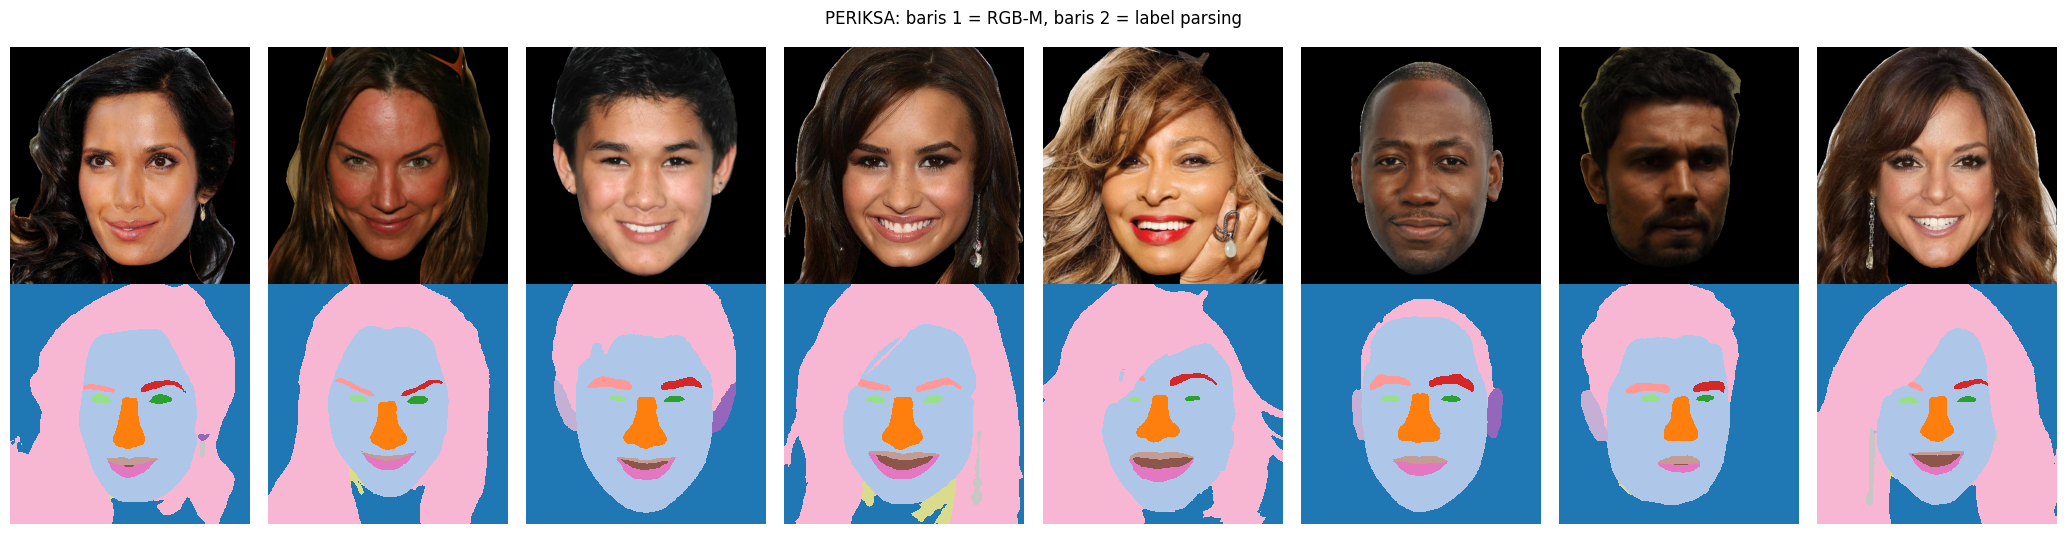

In [10]:
# ============================================================
# 3.4 PARSING SEMUA GAMBAR -> FITUR REGION + CACHE GAMBAR PERSEGI
# ============================================================
REG_CACHE, IMG_CACHE_PATH = RESULT_DIR / "region_features.npz", RESULT_DIR / "img_cache.npy"
reg_meta = json.dumps({"parser": PARSER_HF_ID, "parse": PARSE_SIZE, "cache": CACHE_SIZE, "cols": REGION_COLS,
                       "min": REGION_MIN_PIX, "mask": bool(MASK_OK)}, sort_keys=True)

class SquareDS(Dataset):
    def __init__(self, frame):
        self.paths = [str(p) for p in frame["resolved_path"]]
        self.masks = [str(p) for p in frame["mask_path"]] if MASK_OK else None
    def __len__(self):
        return len(self.paths)
    def __getitem__(self, i):
        big, small, valid = load_squares(self.paths[i], self.masks[i] if self.masks else None)
        return torch.from_numpy(big), torch.from_numpy(small), torch.from_numpy(valid)

REG = IMG_CACHE = None
VIS = []
if REG_CACHE.exists() and IMG_CACHE_PATH.exists() and not RECOMPUTE:
    z = np.load(REG_CACHE, allow_pickle=False)
    if np.array_equal(z["md5"], md5_all) and str(z["meta"]) == reg_meta:
        REG, IMG_CACHE = z["reg"], np.load(IMG_CACHE_PATH)
        print("Cache parsing dipakai.")

if REG is None:
    loader = DataLoader(SquareDS(df), batch_size=PARSE_BATCH, shuffle=False, num_workers=FT_NUM_WORKERS)
    reg_list, img_list, t0 = [], [], time.time()
    for big, small, valid in tqdm(loader, desc="parsing"):
        maps = parse_u8(big)
        big_np, valid_np = big.numpy(), valid.numpy()
        for j in range(len(big_np)):
            reg_list.append(region_color_features(big_np[j], maps[j], REGION_IDS, GLASSES_IDS, valid_np[j]))
            if len(VIS) < 8:
                VIS.append((big_np[j].copy(), maps[j].copy()))
        img_list.append(small.numpy())
    REG, IMG_CACHE = np.stack(reg_list), np.concatenate(img_list)
    np.savez_compressed(REG_CACHE, reg=REG, md5=md5_all, meta=reg_meta)
    np.save(IMG_CACHE_PATH, IMG_CACHE)
    print(f"Parsing selesai dalam {(time.time() - t0) / 60:.1f} menit.")
assert REG.shape == (N_ALL, len(REGION_COLS)) and IMG_CACHE.shape == (N_ALL, CACHE_SIZE, CACHE_SIZE, 3)

found = {r: float(np.isfinite(REG[:, COL_IX[f"{r}_L"]]).mean()) for r in REGION_PARTS}
print("Proporsi gambar dengan region terdeteksi:", {k: round(v, 3) for k, v in found.items()})
if VIS:
    fig, axes = plt.subplots(2, len(VIS), figsize=(2.6 * len(VIS), 5.4))
    for j, (im, mp) in enumerate(VIS):
        axes[0, j].imshow(im); axes[0, j].axis("off")
        axes[1, j].imshow(mp, cmap="tab20", vmin=0, vmax=19, interpolation="nearest"); axes[1, j].axis("off")
    plt.suptitle("PERIKSA: baris 1 = RGB-M, baris 2 = label parsing")
    plt.tight_layout(); plt.show()
del parser; gc.collect()
if USE_AMP:
    torch.cuda.empty_cache()

## 4. Embedding frozen (ViT-S, sama dengan E12)

Dipakai untuk komponen `emb_lr` dan deteksi near-duplicate. Backbone frozen sengaja tetap ViT-S agar ambang `DUP_THR = 0.90` dari E12 tetap bermakna.

In [11]:
# ============================================================
# 4.1 EMBEDDING FROZEN
# ============================================================
emb_meta = json.dumps({"model": FROZEN_HF_ID, "img": EMB_IMG_SIZE, "cache": CACHE_SIZE, "layers": EXTRA_MEAN_LAYERS}, sort_keys=True)
frozen = load_backbone(FROZEN_HF_ID).float().to(DEVICE).eval()
for p in frozen.parameters():
    p.requires_grad_(False)
FZ_HIDDEN = int(frozen.config.hidden_size)
FZ_PREFIX = 1 + int(getattr(frozen.config, "num_register_tokens", 0))

def u8_to_input(batch_u8_np, size):
    x = torch.from_numpy(batch_u8_np).to(DEVICE).permute(0, 3, 1, 2).float() / 255.0
    if x.shape[-1] != size:
        x = F.interpolate(x, size=(size, size), mode="bilinear", antialias=True, align_corners=False)
    return (x - _MEAN_T) / _STD_T

@torch.no_grad()
def embed_u8(batch_u8_np):
    x = u8_to_input(batch_u8_np, EMB_IMG_SIZE)
    acc = None
    for xx in (x, torch.flip(x, dims=[3])):
        out = frozen(pixel_values=xx, output_hidden_states=True)
        last, hs = out.last_hidden_state, out.hidden_states
        f = {"cls_last": last[:, 0], "mean_last": last[:, FZ_PREFIX:].mean(1)}
        for li in EXTRA_MEAN_LAYERS:
            f[f"mean_L{li}"] = hs[li][:, FZ_PREFIX:].mean(1)
        acc = f if acc is None else {k: acc[k] + f[k] for k in f}
    return {k: (v / 2).float().cpu().numpy() for k, v in acc.items()}

EMB_PATH = RESULT_DIR / "frozen_embeddings.npz"
EMB = None
if EMB_PATH.exists() and not RECOMPUTE:
    z = np.load(EMB_PATH, allow_pickle=False)
    if np.array_equal(z["md5"], md5_all) and str(z["meta"]) == emb_meta:
        EMB = {k: z[k] for k in z.files if k not in ("md5", "meta")}
        print("Cache embedding dipakai.")
if EMB is None:
    chunks = {}
    for s in tqdm(range(0, N_ALL, 64), desc="embedding"):
        for k, v in embed_u8(IMG_CACHE[s:s + 64]).items():
            chunks.setdefault(k, []).append(v)
    EMB = {k: np.concatenate(v) for k, v in chunks.items()}
    np.savez_compressed(EMB_PATH, md5=md5_all, meta=emb_meta, **EMB)
del frozen; gc.collect()
if USE_AMP:
    torch.cuda.empty_cache()
print({k: v.shape for k, v in EMB.items()})

config.json:   0%|          | 0.00/743 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 86.4MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/211 [00:00<?, ?it/s]

embedding:   0%|          | 0/77 [00:00<?, ?it/s]

{'cls_last': (4920, 384), 'mean_last': (4920, 384), 'mean_L4': (4920, 384), 'mean_L8': (4920, 384)}


## 5. Grup per orang, holdout, fold CV

Grup dibentuk dari: (1) nama orang di nama file non-CelebA, **tanpa nama generik**; (2) identitas asli CelebA bila file pemetaan tersedia dan lolos uji kecocokan; (3) near-duplicate embedding (`DUP_THR`).

In [12]:
# ============================================================
# 5.1 NEAR-DUPLICATE
# ============================================================
E = EMB["cls_last"].astype(np.float32)
E = E - E[train_rows].mean(0, keepdims=True)
E /= np.clip(np.linalg.norm(E, axis=1, keepdims=True), 1e-8, None)
SIM = E @ E.T
np.fill_diagonal(SIM, -1.0)
iu, ju = np.triu_indices(N_ALL, k=1)
m_sel = SIM[iu, ju] >= DUP_THR
dup_pairs = np.stack([iu[m_sel], ju[m_sel]], axis=1)
n_cross = int((is_train[dup_pairs[:, 0]] != is_train[dup_pairs[:, 1]]).sum())
print(f"Near-duplicate (>= {DUP_THR}): {len(dup_pairs)} pasangan, {n_cross} menyeberang train/test resmi.")
del SIM, iu, ju, m_sel, E; gc.collect()

Near-duplicate (>= 0.9): 109 pasangan, 43 menyeberang train/test resmi.


0

In [13]:
# ============================================================
# 5.2 GRUP PER ORANG -> HOLDOUT -> FOLD CV
# ============================================================
def name_key(rel):
    # "RGB-M/train/autunno/deep/Elisabetta-Canalis 9.png" -> "elisabetta canalis"
    s = Path(str(rel).replace("\\", "/")).stem.lower()
    s = re.sub(r"[_\-.]+", " ", s)
    prev = None
    while prev != s:
        prev = s
        s = re.sub(r"\s*\(?\d+\)?\s*$", "", s).strip()
    return re.sub(r"\s+", " ", s)

is_cel_all = df["celeba"].to_numpy(dtype=bool)
stems = df[MASKED_PATH_COL].map(lambda r: Path(str(r).replace("\\", "/")).stem).to_numpy()
key_groups = {}

# (1) nama file non-CelebA
keys = df[MASKED_PATH_COL].map(name_key).to_numpy()
generic_hits = 0
for i in np.where(~is_cel_all)[0]:
    k = keys[i]
    if len(k) < 3 or k in GENERIC_NAMES or k.isdigit():
        generic_hits += 1
        continue
    key_groups.setdefault("name:" + k, []).append(int(i))
print(f"Foto non-CelebA bernama generik (tidak dikelompokkan lewat nama): {generic_hits}")

# (2) identitas asli CelebA (opsional)
IDENTITY_USED = False
if USE_CELEBA_IDENTITY:
    def find_file(name):
        hits = sorted(KAGGLE_INPUT.rglob(name))
        return hits[0] if hits else None
    f_map, f_id = find_file("CelebA-HQ-to-CelebA-mapping.txt"), find_file("identity_CelebA.txt")
    if f_map is None or f_id is None:
        print("Identitas CelebA: file pemetaan tidak ditemukan di /kaggle/input -> dilewati.")
    else:
        mp = pd.read_csv(f_map, sep=r"\s+")
        ident = pd.read_csv(f_id, sep=r"\s+", header=None, names=["orig_file", "pid"])
        hq = mp.merge(ident, on="orig_file", how="inner")
        hq2pid = dict(zip(hq["idx"].astype(int), hq["pid"].astype(int)))
        pid = np.array([hq2pid.get(int(s), -1) if (c and str(s).isdigit()) else -1 for s, c in zip(stems, is_cel_all)])
        both = [(a, b) for a, b in dup_pairs if pid[a] >= 0 and pid[b] >= 0]
        agree = float(np.mean([pid[a] == pid[b] for a, b in both])) if both else float("nan")
        print(f"Identitas CelebA: {int((pid >= 0).sum())} dari {int(is_cel_all.sum())} foto CelebA terpetakan | "
              f"kecocokan pada {len(both)} pasangan near-duplicate = {agree:.1%}")
        if len(both) >= 5 and agree >= IDENTITY_MIN_AGREEMENT:
            IDENTITY_USED = True
            for i in np.where(pid >= 0)[0]:
                key_groups.setdefault(f"pid:{pid[i]}", []).append(int(i))
            print("-> identitas CelebA DIPAKAI untuk pengelompokan.")
        else:
            print("-> kecocokan rendah (nama file dataset kemungkinan bukan indeks CelebA-HQ) -> identitas TIDAK dipakai.")

edges = [dup_pairs] if len(dup_pairs) else []
for members in key_groups.values():
    if len(members) > 1:
        edges.append(np.array([[members[0], j] for j in members[1:]]))
if edges:
    e = np.concatenate(edges)
    _, lab = connected_components(coo_matrix((np.ones(len(e)), (e[:, 0], e[:, 1])), shape=(N_ALL, N_ALL)), directed=False)
else:
    lab = np.arange(N_ALL)
groups_all = lab.astype(str)
gsize = pd.Series(groups_all).value_counts()
print(f"Grup unik: {len(gsize)} | grup terbesar: {int(gsize.iloc[0])} foto (E12: 396 karena nama 'images')")

# --- Holdout: satu lipatan StratifiedGroupKFold, hanya baris CelebA disisihkan ---
official_train_rows = train_rows.copy()
g_off = groups_all[official_train_rows]
strata_all = (df["joint_label"] + "|" + df["celeba"].astype(int).astype(str)).to_numpy()
n_sp = max(2, int(round(1.0 / HOLDOUT_FRAC)))
sp = StratifiedGroupKFold(n_splits=n_sp, shuffle=True, random_state=SEED + 1)
_, cand = next(iter(sp.split(np.zeros(len(g_off)), strata_all[official_train_rows], groups=g_off)))
ho_local = cand[is_cel_all[official_train_rows][cand]]
hold_groups = set(g_off[ho_local])
keep_local = np.array([i for i in range(len(g_off)) if g_off[i] not in hold_groups])
hold_rows, train_rows = official_train_rows[ho_local], official_train_rows[keep_local]
n_dropped = len(official_train_rows) - len(hold_rows) - len(train_rows)
assert len(set(groups_all[hold_rows]) & set(groups_all[train_rows])) == 0, "Grup bocor antara holdout dan train."

y12 = ALL_Y["y12"][train_rows]
yho = ALL_Y["y12"][hold_rows]
cel = is_cel_all[train_rows]
groups_tr = groups_all[train_rows]
strata = strata_all[train_rows]
print(f"Official train {len(official_train_rows)} -> pengembangan {len(train_rows)} (CelebA {int(cel.sum())}) + holdout {len(hold_rows)}"
      + (f" (+{n_dropped} non-CelebA dibuang karena segrup dengan holdout)" if n_dropped else ""))

splitter = StratifiedGroupKFold(n_splits=N_FOLDS, shuffle=True, random_state=SEED)
folds = list(splitter.split(np.zeros(len(strata)), strata, groups=groups_tr))
fold_id = np.zeros(len(strata), dtype=int)
for k, (_, va) in enumerate(folds):
    fold_id[va] = k
assert all(len(set(groups_tr[tr]) & set(groups_tr[va])) == 0 for tr, va in folds), "Grup bocor antar fold."
FOLD_HASH = hashlib.md5(fold_id.tobytes() + train_rows.astype(np.int64).tobytes()).hexdigest()[:10]
display(pd.DataFrame({"n": np.bincount(fold_id), "n_celeba": np.bincount(fold_id, weights=cel).astype(int)}).T)

Foto non-CelebA bernama generik (tidak dikelompokkan lewat nama): 397
Identitas CelebA: file pemetaan tidak ditemukan di /kaggle/input -> dilewati.
Grup unik: 3665 | grup terbesar: 59 foto (E12: 396 karena nama 'images')
Official train 4008 -> pengembangan 3594 (CelebA 1655) + holdout 414


,0,1,2,3,4
n,750,620,689,749,786
n_celeba,320,333,361,328,313


## 6. Metrik dan komponen klasik

- `emb_lr`: logistic regression di atas embedding frozen ViT-S multi-layer. Loss (log-loss OOF) ditampilkan per nilai C.
- `color_hgb`: gradient boosting di atas fitur Lab per region. Kurva loss train/validasi ditampilkan per fold.

In [14]:
# ============================================================
# 6.1 METRIK DAN HELPER
# ============================================================
def ece_score(correct, conf, n_bins=ECE_BINS):
    edges = np.linspace(0, 1, n_bins + 1)
    ece = 0.0
    for i in range(n_bins):
        m = (conf >= edges[i]) & ((conf < edges[i + 1]) if i < n_bins - 1 else (conf <= edges[i + 1]))
        if m.any():
            ece += m.mean() * abs(correct[m].mean() - conf[m].mean())
    return float(ece)

def topk_hit(y, probs, k):
    idx = np.argsort(-probs, axis=1)[:, :k]
    return float((idx == y[:, None]).any(1).mean())

def full_metrics(y, probs):
    pred, conf = probs.argmax(1), probs.max(1)
    correct = pred == y
    _, rec, f1c, _ = precision_recall_fscore_support(y, pred, labels=list(range(NUM_CLASSES)), zero_division=0)
    tp = np.clip(probs[np.arange(len(y)), y], 1e-12, 1.0)
    return {
        "acc": float(correct.mean()),
        "macro_f1": float(f1c.mean()),
        "top2": topk_hit(y, probs, 2),
        "top3": topk_hit(y, probs, 3),
        "worst3_recall": float(np.sort(rec)[:3].mean()),
        "nll": float(-np.log(tp).mean()),
        "ece": ece_score(correct, conf),
    }

def nll_of(p, y):
    return float(-np.log(np.clip(p[np.arange(len(y)), y], 1e-12, 1)).mean())

def apply_temperature(p, T):
    z = np.log(np.clip(p, 1e-12, 1.0)) / float(T)
    z -= z.max(axis=1, keepdims=True)
    e = np.exp(z)
    return e / e.sum(axis=1, keepdims=True)

def fit_temperature(y, p, lo=0.05, hi=10.0):
    return float(minimize_scalar(lambda T: nll_of(apply_temperature(p, T), y), bounds=(lo, hi), method="bounded").x)

def pool(prob_list, weights):
    z = sum(w * np.log(np.clip(p, 1e-12, 1.0)) for p, w in zip(prob_list, weights))
    z = z - z.max(axis=1, keepdims=True)
    e = np.exp(z)
    return e / e.sum(axis=1, keepdims=True)

def proba_full(model, X):
    p = model.predict_proba(X)
    out = np.zeros((len(X), NUM_CLASSES))
    out[:, model.classes_] = p
    return out

SHOW = ["acc", "macro_f1", "top2", "top3", "worst3_recall", "nll", "ece"]
COMP_OOF, COMP_TEST, COMP_HOLD, COMP_MODEL = {}, {}, {}, {}
print("Helper siap.")

Helper siap.


In [15]:
# ============================================================
# 6.2 KOMPONEN emb_lr (loss = log-loss OOF per C)
# ============================================================
EMB_KEYS = ["cls_last", "mean_last"] + [f"mean_L{l}" for l in EXTRA_MEAN_LAYERS]
X_emb = np.hstack([EMB[k] for k in EMB_KEYS]).astype(np.float64)

def make_lr(C):
    return make_pipeline(StandardScaler(), LogisticRegression(C=C, max_iter=3000))

rows, lr_oofs = [], {}
for C in C_GRID:
    t0 = time.time()
    oof = np.zeros((len(train_rows), NUM_CLASSES))
    fold_loss = []
    for tr, va in folds:
        m = make_lr(C).fit(X_emb[train_rows[tr]], y12[tr])
        oof[va] = proba_full(m, X_emb[train_rows[va]])
        fold_loss.append((nll_of(proba_full(m, X_emb[train_rows[tr]]), y12[tr]), nll_of(oof[va], y12[va])))
    lr_oofs[C] = oof
    rows.append({"C": C, "train_loss": np.mean([a for a, _ in fold_loss]), "val_loss": np.mean([b for _, b in fold_loss]),
                 "val_loss_celeba": nll_of(oof[cel], y12[cel]), "acc_celeba": float((oof[cel].argmax(1) == y12[cel]).mean()),
                 "sec": round(time.time() - t0, 1)})
lr_df = pd.DataFrame(rows)
display(lr_df.round(4))
BEST_C = float(lr_df.sort_values("val_loss_celeba").iloc[0]["C"])
print("C terpilih:", BEST_C)
COMP_OOF["emb_lr"] = lr_oofs[BEST_C]
COMP_MODEL["emb_lr"] = make_lr(BEST_C).fit(X_emb[train_rows], y12)
COMP_TEST["emb_lr"] = proba_full(COMP_MODEL["emb_lr"], X_emb[test_rows])
COMP_HOLD["emb_lr"] = proba_full(COMP_MODEL["emb_lr"], X_emb[hold_rows])

,C,train_loss,val_loss,val_loss_celeba,acc_celeba,sec
0,0.0003,1.7290,1.9833,2.0024,0.2634,30.8
1,0.0010,1.4755,1.9097,1.9670,0.2767,61.9
2,0.0030,1.2105,1.9094,2.0069,0.2792,80.5


C terpilih: 0.001


color_hgb fold 0: iter=143 train_loss=0.5157 val_loss(internal)=1.7723 val_loss(fold)=2.0503
color_hgb fold 1: iter=158 train_loss=0.4756 val_loss(internal)=1.8044 val_loss(fold)=1.9552
color_hgb fold 2: iter=161 train_loss=0.4418 val_loss(internal)=1.7705 val_loss(fold)=1.9564
color_hgb fold 3: iter=141 train_loss=0.5099 val_loss(internal)=1.7359 val_loss(fold)=1.9575
color_hgb fold 4: iter=145 train_loss=0.5244 val_loss(internal)=1.7634 val_loss(fold)=1.8739


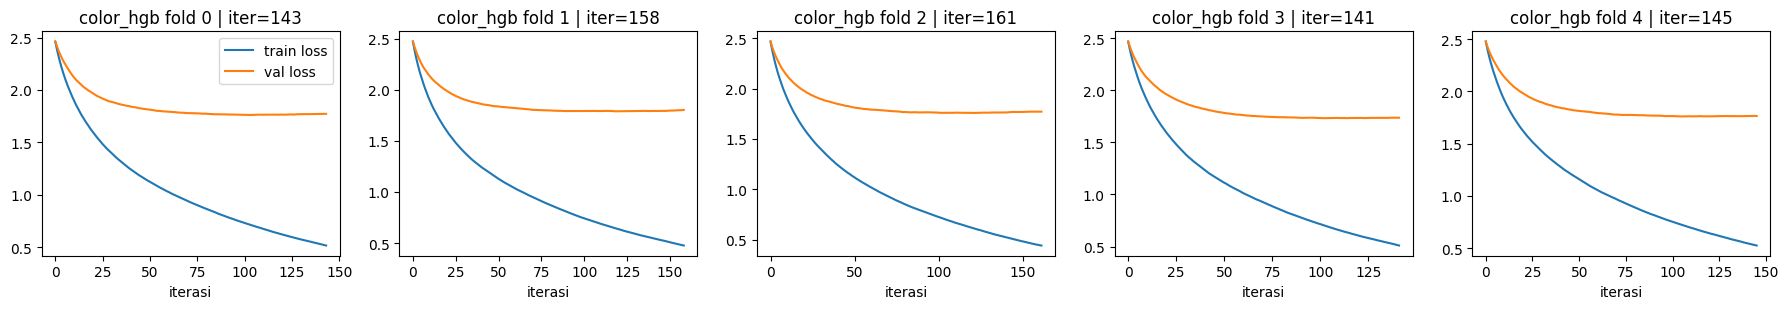

,acc,macro_f1,top2,top3,worst3_recall,nll,ece
emb_lr,0.2767,0.2519,0.4888,0.6211,0.1222,1.9670,0.0508
color_hgb,0.2991,0.2857,0.4943,0.6218,0.1714,2.0381,0.1284


OOF subset CelebA.


In [16]:
# ============================================================
# 6.3 KOMPONEN color_hgb (kurva loss train/validasi per fold)
# ============================================================
REG_KEEP = np.where(np.isfinite(REG[train_rows]).mean(0) >= 0.02)[0]
X_reg = REG[:, REG_KEEP].astype(np.float64)

def make_hgb():
    return HistGradientBoostingClassifier(learning_rate=0.04, max_iter=600, max_depth=4, l2_regularization=1.0,
                                          max_leaf_nodes=15, min_samples_leaf=25, early_stopping=True,
                                          scoring="loss", validation_fraction=0.15, n_iter_no_change=40,
                                          random_state=SEED)

oof = np.zeros((len(train_rows), NUM_CLASSES))
fig, axes = plt.subplots(1, len(folds), figsize=(3.6 * len(folds), 3.2), squeeze=False)
for k, (tr, va) in enumerate(folds):
    m = make_hgb().fit(X_reg[train_rows[tr]], y12[tr])
    oof[va] = proba_full(m, X_reg[train_rows[va]])
    ax = axes[0, k]
    ax.plot(-m.train_score_, label="train loss"); ax.plot(-m.validation_score_, label="val loss")
    ax.set_title(f"color_hgb fold {k} | iter={m.n_iter_}"); ax.set_xlabel("iterasi")
    print(f"color_hgb fold {k}: iter={m.n_iter_} train_loss={-m.train_score_[-1]:.4f} "
          f"val_loss(internal)={-m.validation_score_[-1]:.4f} val_loss(fold)={nll_of(oof[va], y12[va]):.4f}")
axes[0, 0].legend(); plt.tight_layout(); plt.show()
COMP_OOF["color_hgb"] = oof
COMP_MODEL["color_hgb"] = make_hgb().fit(X_reg[train_rows], y12)
COMP_TEST["color_hgb"] = proba_full(COMP_MODEL["color_hgb"], X_reg[test_rows])
COMP_HOLD["color_hgb"] = proba_full(COMP_MODEL["color_hgb"], X_reg[hold_rows])

display(pd.DataFrame({k: {s: full_metrics(y12[cel], v[cel])[s] for s in SHOW} for k, v in COMP_OOF.items()}).T.round(4))
print("OOF subset CelebA.")

## 7. Fine-tuning fusion (DINOv3 ViT-B + Lab per region)

Arsitektur:
- **Cabang gambar**: DINOv3 dilatih penuh dengan layer-wise LR decay; fitur = [CLS, rata-rata patch].
- **Cabang warna**: fitur Lab per region (diisi median + indikator hilang, distandarkan per fold) → MLP. Saat training, cabang ini dimatikan acak dengan peluang `FT_COLOR_DROP` agar model tetap belajar dari gambar.
- **Logit hierarkis**: `logit[k] = head12[k] + headS[season(k)] + headC[karakter(k)] + headU[undertone(k)]`. Kelas yang berbagi season/karakteristik/undertone saling berbagi bukti, sehingga sinyal undertone dan Lab langsung menaikkan skor sub-season.
- **Loss**: cross-entropy 12 kelas dengan label smoothing hierarkis + `FT_AUX_W` × (CE season + CE karakteristik + CE undertone).
- **EMA** bobot dipakai untuk validasi dan prediksi.

Tiap epoch mencetak **train loss** (total dan CE 12 kelas) serta **val loss** (CE 12 kelas tanpa smoothing), val acc, dan val acc CelebA. Kurva per fold diplot di akhir.

In [17]:
# ============================================================
# 7.1 DATASET, MODEL, LOSS, LOOP TRAINING
# ============================================================
train_tf = transforms.Compose([
    transforms.RandomRotation(8),
    transforms.RandomResizedCrop(FT_IMG_SIZE, scale=(0.6, 1.0), ratio=(0.9, 1.1), antialias=True),
    transforms.RandomHorizontalFlip(),
    transforms.ToTensor(),
    transforms.Normalize(IMNET_MEAN, IMNET_STD),
])
eval_tf = transforms.Compose([
    transforms.Resize((FT_IMG_SIZE, FT_IMG_SIZE), antialias=True),
    transforms.ToTensor(),
    transforms.Normalize(IMNET_MEAN, IMNET_STD),
])

class ColorPrep:
    # Isi NaN dengan median train, standarkan, tambah indikator hilang. Di-fit per fold (hanya baris train fold).
    def fit(self, X):
        self.keep = np.where(np.isfinite(X).mean(0) >= 0.02)[0]
        Xk = X[:, self.keep]
        self.med = np.nanmedian(Xk, axis=0)
        self.miss = np.where(~np.isfinite(Xk).all(0))[0]
        Z = np.where(np.isfinite(Xk), Xk, self.med)
        self.mu, self.sd = Z.mean(0), Z.std(0) + 1e-6
        return self
    def transform(self, X):
        Xk = X[:, self.keep]
        Z = np.clip((np.where(np.isfinite(Xk), Xk, self.med) - self.mu) / self.sd, -5, 5)
        M = (~np.isfinite(Xk[:, self.miss])).astype(np.float64)
        return np.hstack([Z, M]).astype(np.float32)
    @property
    def dim(self):
        return len(self.keep) + len(self.miss)

class FTDataset(Dataset):
    def __init__(self, rows, train, colorZ):
        self.rows, self.tf, self.colorZ = np.asarray(rows), (train_tf if train else eval_tf), colorZ
    def __len__(self):
        return len(self.rows)
    def __getitem__(self, i):
        r = int(self.rows[i])
        x = self.tf(Image.fromarray(IMG_CACHE[r]))
        return (x, torch.from_numpy(self.colorZ[r]), int(ALL_Y["y12"][r]), int(ALL_Y["yS"][r]),
                int(ALL_Y["yC"][r]), int(ALL_Y["yU"][r]))

class FusionNet(nn.Module):
    def __init__(self, backbone, color_dim):
        super().__init__()
        self.backbone = backbone
        d = int(backbone.config.hidden_size)
        self.n_prefix = 1 + int(getattr(backbone.config, "num_register_tokens", 0))
        self.use_color = FT_USE_COLOR and color_dim > 0
        feat = 2 * d
        if self.use_color:
            self.color_mlp = nn.Sequential(nn.Linear(color_dim, FT_COLOR_HIDDEN), nn.GELU(), nn.Dropout(FT_DROPOUT),
                                           nn.Linear(FT_COLOR_HIDDEN, FT_COLOR_HIDDEN), nn.GELU())
            feat += FT_COLOR_HIDDEN
        self.norm = nn.LayerNorm(feat)
        self.drop = nn.Dropout(FT_DROPOUT)
        self.head12 = nn.Linear(feat, NUM_CLASSES)
        self.headS = nn.Linear(feat, NUM_SEASONS)
        self.headC = nn.Linear(feat, NUM_CHARS)
        self.headU = nn.Linear(feat, 2)
        self.register_buffer("season_of", torch.as_tensor(season_of, dtype=torch.long))
        self.register_buffer("char_of", torch.as_tensor(char_of, dtype=torch.long))
        self.register_buffer("warm_of", torch.as_tensor(warm_of, dtype=torch.long))

    def forward(self, x, c):
        h = self.backbone(pixel_values=x).last_hidden_state
        f = torch.cat([h[:, 0], h[:, self.n_prefix:].mean(1)], dim=1)
        if self.use_color:
            if self.training and FT_COLOR_DROP > 0:
                c = c * (torch.rand(c.shape[0], 1, device=c.device) >= FT_COLOR_DROP).to(c.dtype)
            f = torch.cat([f, self.color_mlp(c)], dim=1)
        f = self.drop(self.norm(f))
        z12, zS, zC, zU = self.head12(f), self.headS(f), self.headC(f), self.headU(f)
        if FT_HIER_LOGITS:
            z12 = z12 + zS[:, self.season_of] + zC[:, self.char_of] + zU[:, self.warm_of]
        return z12, zS, zC, zU

def build_soft_targets():
    if not FT_HIER_SMOOTH:
        W = np.ones((NUM_CLASSES, NUM_CLASSES))
    else:
        W = (1.0 + (season_of[:, None] == season_of[None, :]) * 1.0
             + (char_of[:, None] == char_of[None, :]) * 1.0
             + (warm_of[:, None] == warm_of[None, :]) * 0.5)
    np.fill_diagonal(W, 0.0)
    W = W / W.sum(1, keepdims=True)
    return torch.tensor((1 - FT_LABEL_SMOOTH) * np.eye(NUM_CLASSES) + FT_LABEL_SMOOTH * W, dtype=torch.float32)

SOFT_T = build_soft_targets().to(DEVICE)

def loss_fn(outs, a, b, c, d):
    o12, oS, oC, oU = (o.float() for o in outs)
    ce12 = -(SOFT_T[a] * F.log_softmax(o12, dim=1)).sum(1).mean()
    aux = F.cross_entropy(oS, b) + F.cross_entropy(oC, c) + F.cross_entropy(oU, d)
    return ce12 + FT_AUX_W * aux, ce12

def build_optimizer(model):
    n_layers = int(model.backbone.config.num_hidden_layers)
    groups, matched = {}, 0
    for name, p in model.backbone.named_parameters():
        m = re.search(r"(?:^|\.)layers?\.(\d+)\.", name)
        if m:
            depth, matched = int(m.group(1)) + 1, matched + 1
        elif "embed" in name:
            depth = 0
        else:
            depth = n_layers
        lr = FT_LR_BACKBONE * (FT_LLRD ** (n_layers - depth))
        groups.setdefault((lr, 0.0 if p.ndim <= 1 else FT_WD), []).append(p)
    if matched == 0:
        print("PERINGATAN: nama layer tidak dikenali; semua layer backbone memakai LR yang sama.")
    for name, p in model.named_parameters():
        if not name.startswith("backbone."):
            groups.setdefault((FT_LR_HEAD, 0.0 if p.ndim <= 1 else FT_WD), []).append(p)
    return torch.optim.AdamW([{"params": ps, "lr": lr, "weight_decay": wd} for (lr, wd), ps in groups.items()])

def make_scaler():
    try:
        return torch.amp.GradScaler("cuda", enabled=USE_AMP)
    except Exception:
        return torch.cuda.amp.GradScaler(enabled=USE_AMP)

@torch.no_grad()
def ema_update(ema_m, m, decay):
    msd = m.state_dict()
    for k, v in ema_m.state_dict().items():
        if v.dtype.is_floating_point:
            v.mul_(decay).add_(msd[k].detach(), alpha=1 - decay)
        else:
            v.copy_(msd[k])

@torch.no_grad()
def predict_rows(model, rows, colorZ, tta=True):
    model.eval()
    loader = DataLoader(FTDataset(rows, False, colorZ), batch_size=128, shuffle=False, num_workers=FT_NUM_WORKERS)
    outs = []
    for batch in loader:
        x, c = batch[0].to(DEVICE, non_blocking=True), batch[1].to(DEVICE, non_blocking=True)
        with torch.autocast(device_type=DEVICE.type, dtype=torch.float16, enabled=USE_AMP):
            p = model(x, c)[0].float().softmax(1)
            if tta:
                p = (p + model(torch.flip(x, dims=[3]), c)[0].float().softmax(1)) / 2
        outs.append(p.cpu().numpy().astype(np.float64))
    return np.concatenate(outs) if outs else np.zeros((0, NUM_CLASSES))

def train_one(tr_rows, va_rows, colorZ, color_dim, seed, tag):
    torch.manual_seed(seed); np.random.seed(seed); random.seed(seed)
    model = FusionNet(load_backbone(FT_HF_ID).float(), color_dim).to(DEVICE)
    ema = copy.deepcopy(model).eval() if FT_EMA > 0 else None
    if ema is not None:
        for p in ema.parameters():
            p.requires_grad_(False)
    opt = build_optimizer(model)
    loader = DataLoader(FTDataset(tr_rows, True, colorZ), batch_size=FT_BATCH, shuffle=True, drop_last=True,
                        num_workers=FT_NUM_WORKERS, pin_memory=USE_AMP, persistent_workers=FT_NUM_WORKERS > 0)
    total, warm = FT_EPOCHS * len(loader), max(1, FT_WARMUP_EPOCHS * len(loader))
    sched = torch.optim.lr_scheduler.LambdaLR(
        opt, lambda s: (s + 1) / warm if s < warm else 0.5 * (1 + math.cos(math.pi * (s - warm) / max(1, total - warm))))
    scaler, hist, step = make_scaler(), [], 0
    va_y, va_cel = ALL_Y["y12"][va_rows], is_cel_all[va_rows]
    for ep in range(FT_EPOCHS):
        model.train()
        run, run12, n = 0.0, 0.0, 0
        for x, cz, a, b, c, d in loader:
            x, cz = x.to(DEVICE, non_blocking=True), cz.to(DEVICE, non_blocking=True)
            a, b, c, d = a.to(DEVICE), b.to(DEVICE), c.to(DEVICE), d.to(DEVICE)
            with torch.autocast(device_type=DEVICE.type, dtype=torch.float16, enabled=USE_AMP):
                outs = model(x, cz)
            loss, ce12 = loss_fn(outs, a, b, c, d)
            opt.zero_grad(set_to_none=True)
            scaler.scale(loss).backward()
            scaler.unscale_(opt)
            torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            scaler.step(opt); scaler.update(); sched.step()
            step += 1
            if ema is not None:
                ema_update(ema, model, min(FT_EMA, (1 + step) / (10 + step)))
            run, run12, n = run + float(loss.detach()) * len(x), run12 + float(ce12.detach()) * len(x), n + len(x)
        pv = predict_rows(ema if ema is not None else model, va_rows, colorZ, tta=False)
        ok = pv.argmax(1) == va_y
        hist.append({"tag": tag, "epoch": ep + 1, "train_loss": run / max(n, 1), "train_ce12": run12 / max(n, 1),
                     "val_loss": nll_of(pv, va_y), "val_acc": float(ok.mean()),
                     "val_acc_celeba": float(ok[va_cel].mean()) if va_cel.any() else float("nan")})
        hh = hist[-1]
        print(f"  [{tag}] epoch {ep + 1:2d}/{FT_EPOCHS} train_loss={hh['train_loss']:.4f} train_ce12={hh['train_ce12']:.4f} "
              f"val_loss={hh['val_loss']:.4f} val_acc={hh['val_acc']:.4f} val_acc_celeba={hh['val_acc_celeba']:.4f}")
    final = ema if ema is not None else model
    del opt, model
    return final, hist

print("Fungsi fine-tuning siap. Soft target (baris 0):", np.round(SOFT_T[0].cpu().numpy(), 3))

Fungsi fine-tuning siap. Soft target (baris 0): [0.9   0.015 0.015 0.006 0.006 0.006 0.006 0.006 0.012 0.009 0.009 0.009]


In [18]:
# ============================================================
# 7.2 FINE-TUNING K-FOLD x SEED (cache per fold: aman dilanjutkan bila sesi terputus)
# ============================================================
ft_meta = json.dumps({"model": FT_HF_ID, "img": FT_IMG_SIZE, "ep": FT_EPOCHS, "bs": FT_BATCH,
                      "lr": [FT_LR_HEAD, FT_LR_BACKBONE, FT_LLRD], "wd": FT_WD, "ls": FT_LABEL_SMOOTH,
                      "hs": FT_HIER_SMOOTH, "hl": FT_HIER_LOGITS, "color": [FT_USE_COLOR, FT_COLOR_HIDDEN, FT_COLOR_DROP],
                      "drop": FT_DROPOUT, "aux": FT_AUX_W, "ema": FT_EMA, "folds": FOLD_HASH, "n": N_ALL,
                      "regcols": len(REGION_COLS), "hold": int(len(hold_rows))}, sort_keys=True)

oof_sum = np.zeros((len(train_rows), NUM_CLASSES))
test_sum, hold_sum, n_models = np.zeros((len(test_rows), NUM_CLASSES)), np.zeros((len(hold_rows), NUM_CLASSES)), 0
FT_HIST, COLOR_PREPS = [], {}
t_start = time.time()
for seed in FT_SEEDS:
    for k, (tr, va) in enumerate(folds):
        prep = ColorPrep().fit(REG[train_rows[tr]])
        COLOR_PREPS[k] = prep
        colorZ = prep.transform(REG)
        cache, ckpt = RESULT_DIR / f"ft_s{seed}_f{k}.npz", RESULT_DIR / f"ft_s{seed}_f{k}.pt"
        if cache.exists() and not RECOMPUTE and (ckpt.exists() or not FT_SAVE_CKPT):
            z = np.load(cache, allow_pickle=False)
            if str(z["meta"]) == ft_meta and np.array_equal(z["va"], va):
                oof_sum[va] += z["p_va"]; test_sum += z["p_te"]; hold_sum += z["p_ho"]; n_models += 1
                FT_HIST += json.loads(str(z["hist"]))
                print(f"seed {seed} fold {k}: cache dipakai.")
                continue
        t0 = time.time()
        model, hist = train_one(train_rows[tr], train_rows[va], colorZ, prep.dim, seed * 100 + k, f"s{seed}f{k}")
        p_va = predict_rows(model, train_rows[va], colorZ)
        p_te = predict_rows(model, test_rows, colorZ)
        p_ho = predict_rows(model, hold_rows, colorZ)
        np.savez_compressed(cache, va=va, p_va=p_va, p_te=p_te, p_ho=p_ho, meta=ft_meta, hist=json.dumps(hist))
        if FT_SAVE_CKPT:
            torch.save({n: (v.half() if v.is_floating_point() else v) for n, v in model.state_dict().items()}, ckpt)
        oof_sum[va] += p_va; test_sum += p_te; hold_sum += p_ho; n_models += 1
        FT_HIST += hist
        print(f"seed {seed} fold {k}: selesai {(time.time() - t0) / 60:.1f} menit | "
              f"val_loss (TTA) = {nll_of(p_va, y12[va]):.4f} | acc fold (TTA) = {(p_va.argmax(1) == y12[va]).mean():.4f}")
        del model; gc.collect()
        if USE_AMP:
            torch.cuda.empty_cache()

COMP_OOF["ft_fusion"] = oof_sum / len(FT_SEEDS)
COMP_TEST["ft_fusion"] = test_sum / n_models
COMP_HOLD["ft_fusion"] = hold_sum / n_models
print(f"Fine-tuning total {(time.time() - t_start) / 60:.1f} menit.")

config.json:   0%|          | 0.00/744 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  343MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/211 [00:00<?, ?it/s]

/tmp/ipykernel_23/1361273235.py:178: UserWarning: Detected call of `lr_scheduler.step()` before `optimizer.step()`. In PyTorch 1.1.0 and later, you should call them in the opposite order: `optimizer.step()` before `lr_scheduler.step()`.  Failure to do this will result in PyTorch skipping the first value of the learning rate schedule. See more details at https://pytorch.org/docs/stable/optim.html#how-to-adjust-learning-rate
  scaler.step(opt); scaler.update(); sched.step()


  [s42f0] epoch  1/15 train_loss=3.4464 train_ce12=2.3979 val_loss=2.1698 val_acc=0.2773 val_acc_celeba=0.2906
  [s42f0] epoch  2/15 train_loss=3.0158 train_ce12=2.1600 val_loss=1.9703 val_acc=0.3413 val_acc_celeba=0.3094
  [s42f0] epoch  3/15 train_loss=2.7409 train_ce12=1.9666 val_loss=1.9651 val_acc=0.3347 val_acc_celeba=0.3219
  [s42f0] epoch  4/15 train_loss=2.4635 train_ce12=1.7542 val_loss=1.9218 val_acc=0.3360 val_acc_celeba=0.3063
  [s42f0] epoch  5/15 train_loss=2.3142 train_ce12=1.6442 val_loss=1.9340 val_acc=0.3413 val_acc_celeba=0.3063
  [s42f0] epoch  6/15 train_loss=2.1896 train_ce12=1.5620 val_loss=1.9847 val_acc=0.3427 val_acc_celeba=0.3094
  [s42f0] epoch  7/15 train_loss=2.0201 train_ce12=1.4310 val_loss=2.0174 val_acc=0.3413 val_acc_celeba=0.3031
  [s42f0] epoch  8/15 train_loss=1.9137 train_ce12=1.3563 val_loss=2.0523 val_acc=0.3480 val_acc_celeba=0.3281
  [s42f0] epoch  9/15 train_loss=1.7635 train_ce12=1.2394 val_loss=2.0482 val_acc=0.3400 val_acc_celeba=0.3031
 

... (14 outputs left out)

Loading weights:   0%|          | 0/211 [00:00<?, ?it/s]

  [s7f3] epoch  1/15 train_loss=3.5199 train_ce12=2.4580 val_loss=1.8793 val_acc=0.3485 val_acc_celeba=0.3018
  [s7f3] epoch  2/15 train_loss=2.9434 train_ce12=2.0939 val_loss=1.8181 val_acc=0.3832 val_acc_celeba=0.3262
  [s7f3] epoch  3/15 train_loss=2.6761 train_ce12=1.9034 val_loss=1.8029 val_acc=0.4032 val_acc_celeba=0.3293
  [s7f3] epoch  4/15 train_loss=2.5667 train_ce12=1.8349 val_loss=1.8298 val_acc=0.3832 val_acc_celeba=0.3171
  [s7f3] epoch  5/15 train_loss=2.3393 train_ce12=1.6629 val_loss=1.8811 val_acc=0.4005 val_acc_celeba=0.3415
  [s7f3] epoch  6/15 train_loss=2.1849 train_ce12=1.5464 val_loss=1.9004 val_acc=0.3845 val_acc_celeba=0.3171
  [s7f3] epoch  7/15 train_loss=2.0397 train_ce12=1.4380 val_loss=1.9175 val_acc=0.3832 val_acc_celeba=0.3232
  [s7f3] epoch  8/15 train_loss=1.9051 train_ce12=1.3386 val_loss=1.9182 val_acc=0.3912 val_acc_celeba=0.3262
  [s7f3] epoch  9/15 train_loss=1.7983 train_ce12=1.2591 val_loss=1.9397 val_acc=0.3899 val_acc_celeba=0.3293
  [s7f3] e

Loading weights:   0%|          | 0/211 [00:00<?, ?it/s]

  [s7f4] epoch  1/15 train_loss=3.5063 train_ce12=2.4479 val_loss=1.8861 val_acc=0.3295 val_acc_celeba=0.3163
  [s7f4] epoch  2/15 train_loss=3.0124 train_ce12=2.1471 val_loss=1.7416 val_acc=0.3995 val_acc_celeba=0.3514
  [s7f4] epoch  3/15 train_loss=2.7317 train_ce12=1.9418 val_loss=1.7617 val_acc=0.4071 val_acc_celeba=0.3259
  [s7f4] epoch  4/15 train_loss=2.5663 train_ce12=1.8214 val_loss=1.7140 val_acc=0.4224 val_acc_celeba=0.3387
  [s7f4] epoch  5/15 train_loss=2.4135 train_ce12=1.7147 val_loss=1.7688 val_acc=0.4084 val_acc_celeba=0.3514
  [s7f4] epoch  6/15 train_loss=2.2409 train_ce12=1.5827 val_loss=1.7363 val_acc=0.4059 val_acc_celeba=0.3259
  [s7f4] epoch  7/15 train_loss=2.0924 train_ce12=1.4677 val_loss=1.7782 val_acc=0.4071 val_acc_celeba=0.3227
  [s7f4] epoch  8/15 train_loss=1.9645 train_ce12=1.3769 val_loss=1.8051 val_acc=0.4084 val_acc_celeba=0.3227
  [s7f4] epoch  9/15 train_loss=1.8229 train_ce12=1.2716 val_loss=1.8310 val_acc=0.4059 val_acc_celeba=0.3195
  [s7f4] e

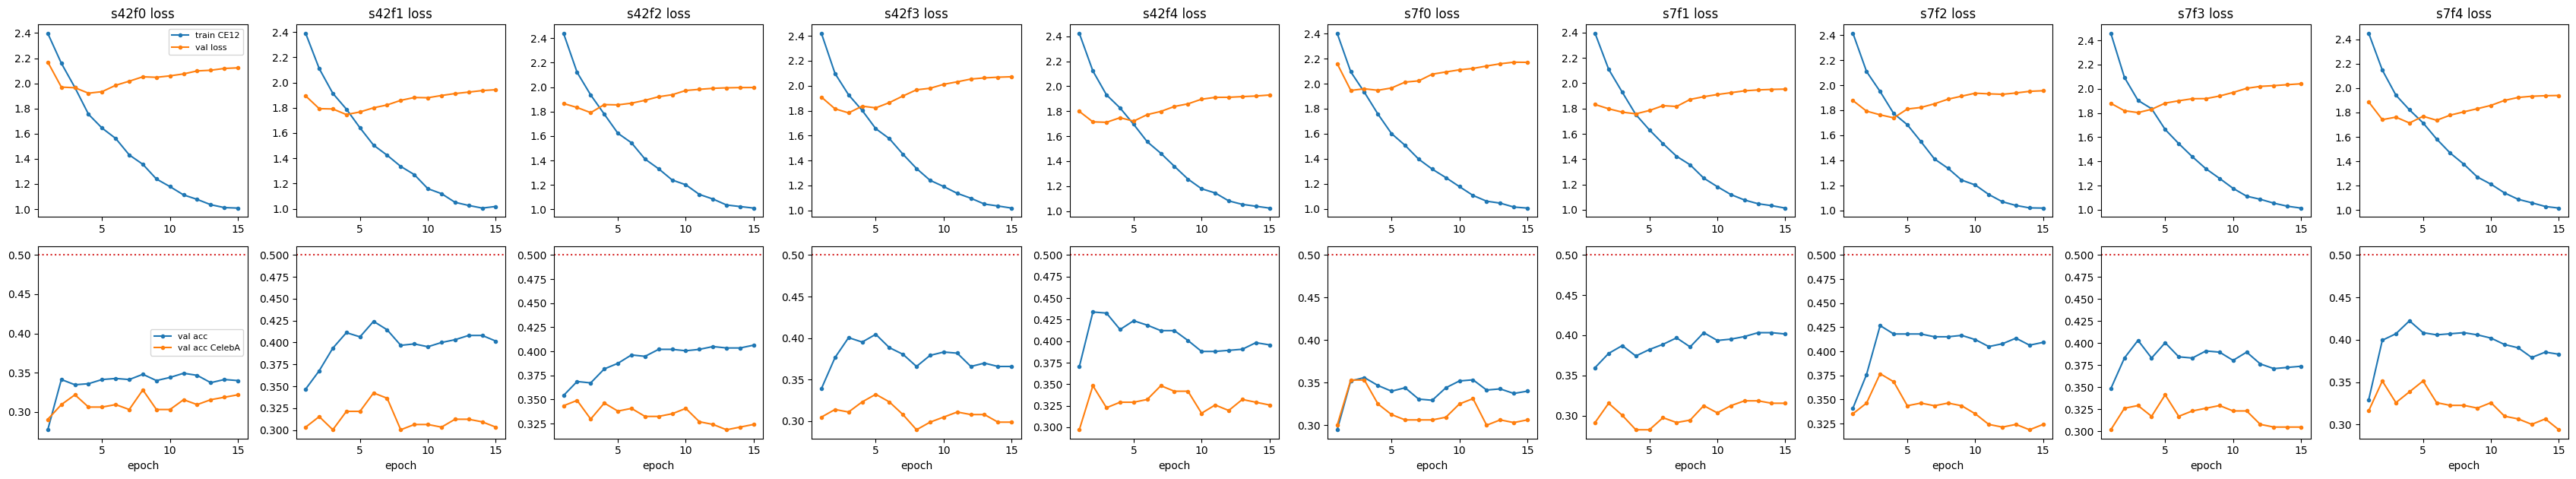

,train_loss,train_ce12,val_loss,val_acc,val_acc_celeba
epoch,,,,,
1,3.4709,2.4188,1.9271,0.3361,0.3084
2,2.9682,2.1166,1.8222,0.3776,0.3328
3,2.7143,1.9330,1.8098,0.3909,0.3271
4,2.5162,1.7889,1.8097,0.3882,0.3258
5,2.3351,1.6553,1.8307,0.3913,0.3258
6,2.1833,1.5450,1.8583,0.3911,0.3241
7,2.0326,1.4316,1.8833,0.3876,0.3215
8,1.9124,1.3442,1.9196,0.3854,0.3188
9,1.7867,1.2519,1.9375,0.3880,0.3199


Rata-rata fold: val_loss terendah di epoch 4 dari 15.
-> val_loss memuncak jauh sebelum epoch terakhir: pertimbangkan FT_EPOCHS lebih kecil atau FT_LR_BACKBONE lebih rendah.


,acc,macro_f1,top2,top3,worst3_recall,nll,ece
emb_lr,0.2767,0.2519,0.4888,0.6211,0.1222,1.9670,0.0508
color_hgb,0.2991,0.2857,0.4943,0.6218,0.1714,2.0381,0.1284
ft_fusion,0.3130,0.2978,0.5124,0.6471,0.1911,2.2145,0.2166


In [19]:
# ============================================================
# 7.3 KURVA LOSS DAN AKURASI PER FOLD
# ============================================================
H = pd.DataFrame(FT_HIST)
H.to_csv(RESULT_DIR / "E13_ft_history.csv", index=False)
tags = H["tag"].unique().tolist()
fig, axes = plt.subplots(2, len(tags), figsize=(3.4 * len(tags), 6.4), squeeze=False)
for j, t in enumerate(tags):
    h = H[H["tag"] == t]
    axes[0, j].plot(h["epoch"], h["train_ce12"], "o-", ms=3, label="train CE12")
    axes[0, j].plot(h["epoch"], h["val_loss"], "o-", ms=3, label="val loss")
    axes[0, j].set_title(f"{t} loss")
    axes[1, j].plot(h["epoch"], h["val_acc"], "o-", ms=3, label="val acc")
    axes[1, j].plot(h["epoch"], h["val_acc_celeba"], "o-", ms=3, label="val acc CelebA")
    axes[1, j].axhline(TARGET_ACC, ls=":", color="tab:red")
    axes[1, j].set_xlabel("epoch")
axes[0, 0].legend(fontsize=8); axes[1, 0].legend(fontsize=8)
plt.tight_layout(); plt.savefig(RESULT_DIR / "E13_ft_curves.png", dpi=110); plt.show()

mean_h = H.groupby("epoch")[["train_loss", "train_ce12", "val_loss", "val_acc", "val_acc_celeba"]].mean()
display(mean_h.round(4))
best_ep = int(mean_h["val_loss"].idxmin())
print(f"Rata-rata fold: val_loss terendah di epoch {best_ep} dari {FT_EPOCHS}.")
if best_ep <= FT_EPOCHS - 4:
    print("-> val_loss memuncak jauh sebelum epoch terakhir: pertimbangkan FT_EPOCHS lebih kecil atau FT_LR_BACKBONE lebih rendah.")

display(pd.DataFrame({k: {s: full_metrics(y12[cel], v[cel])[s] for s in SHOW} for k, v in COMP_OOF.items()}).T.round(4))

## 8. Ensemble log-linear + temperature (semua dari OOF CelebA)

In [20]:
# ============================================================
# 8.1 ENSEMBLE
# ============================================================
COMP_NAMES = list(COMP_OOF.keys())
COMP_T = {n: fit_temperature(y12[cel], COMP_OOF[n][cel]) for n in COMP_NAMES}
print("Temperature per komponen:", {n: round(t, 3) for n, t in COMP_T.items()})
oofs = [apply_temperature(COMP_OOF[n], COMP_T[n]) for n in COMP_NAMES]

steps = int(round(1 / ENS_STEP))
grid = [tuple(np.array(c) / steps) for c in itertools.product(range(steps + 1), repeat=len(COMP_NAMES)) if sum(c) == steps]
rows = []
for w in grid:
    p = pool([o[cel] for o in oofs], w)
    rows.append({**{f"w_{n}": wi for n, wi in zip(COMP_NAMES, w)}, "nll": nll_of(p, y12[cel]),
                 "acc": float((p.argmax(1) == y12[cel]).mean())})
ens_df = pd.DataFrame(rows).sort_values("nll").reset_index(drop=True)
display(ens_df.head(8).round(4))
ENS_W = tuple(float(ens_df.loc[0, f"w_{n}"]) for n in COMP_NAMES)
print("Bobot ensemble (NLL OOF terendah):", dict(zip(COMP_NAMES, ENS_W)))
print("Akurasi OOF tertinggi di grid:", round(ens_df["acc"].max(), 4), "(tidak dipakai untuk memilih bobot: rawan overfit ke OOF)")

def final_predict(comp):
    raw = pool([apply_temperature(comp[n], COMP_T[n]) for n in COMP_NAMES], ENS_W)
    return apply_temperature(raw, TEMP)

TEMP = 1.0
TEMP = fit_temperature(y12[cel], final_predict(COMP_OOF)[cel])
p_oof = final_predict(COMP_OOF)
table = {n: full_metrics(y12[cel], COMP_OOF[n][cel]) for n in COMP_NAMES}
table["ensemble"] = full_metrics(y12[cel], p_oof[cel])
oof_table = pd.DataFrame(table).T[SHOW]
display(oof_table.round(4))
oof_table.to_csv(RESULT_DIR / "E13_oof_celeba.csv")
print(f"Temperature akhir T = {TEMP:.3f}. Angka di atas = OOF subset CelebA.")

Temperature per komponen: {'emb_lr': 1.077, 'color_hgb': 1.417, 'ft_fusion': 1.898}


,w_emb_lr,w_color_hgb,w_ft_fusion,nll,acc
0,0.3,0.4,0.3,1.8675,0.3426
1,0.4,0.3,0.3,1.8677,0.3468
2,0.3,0.3,0.4,1.8679,0.3474
3,0.2,0.4,0.4,1.8705,0.3444
4,0.4,0.4,0.2,1.8708,0.3450
5,0.4,0.2,0.4,1.8718,0.3378
6,0.2,0.5,0.3,1.8737,0.3474
7,0.5,0.3,0.2,1.8737,0.3366


Bobot ensemble (NLL OOF terendah): {'emb_lr': 0.3, 'color_hgb': 0.4, 'ft_fusion': 0.3}
Akurasi OOF tertinggi di grid: 0.3474 (tidak dipakai untuk memilih bobot: rawan overfit ke OOF)


,acc,macro_f1,top2,top3,worst3_recall,nll,ece
emb_lr,0.2767,0.2519,0.4888,0.6211,0.1222,1.9670,0.0508
color_hgb,0.2991,0.2857,0.4943,0.6218,0.1714,2.0381,0.1284
ft_fusion,0.3130,0.2978,0.5124,0.6471,0.1911,2.2145,0.2166
ensemble,0.3426,0.3269,0.5559,0.6792,0.2163,1.8437,0.0421


Temperature akhir T = 0.776. Angka di atas = OOF subset CelebA.


## 9. Holdout dan official test — label dipakai mulai di sini

In [21]:
# ============================================================
# 9.1 METRIK HOLDOUT DAN TEST + CI BOOTSTRAP
# ============================================================
def bootstrap_ci(y, p, seed=SEED):
    rng = np.random.default_rng(seed)
    pred, m = p.argmax(1), full_metrics(y, p)
    ok, top3 = pred == y, (np.argsort(-p, axis=1)[:, :3] == y[:, None]).any(1)
    boot = {"acc": [], "macro_f1": [], "top3": []}
    for _ in range(N_BOOT):
        ix = rng.integers(0, len(y), len(y))
        boot["acc"].append(ok[ix].mean())
        boot["macro_f1"].append(sk_f1_score(y[ix], pred[ix], average="macro", labels=list(range(NUM_CLASSES)), zero_division=0))
        boot["top3"].append(top3[ix].mean())
    return pd.DataFrame({k: {"nilai": m[k], "ci95_lo": np.percentile(v, 2.5), "ci95_hi": np.percentile(v, 97.5)} for k, v in boot.items()}).T

def variants(comp):
    out = {n: comp[n] for n in COMP_NAMES}
    out["ensemble"] = final_predict(comp)
    return out

maj = lambda v: float(np.bincount(v, minlength=NUM_CLASSES).max() / len(v))

var_ho = variants(COMP_HOLD)
p_hold = var_ho["ensemble"]
hold_table = pd.DataFrame({n: full_metrics(yho, p) for n, p in var_ho.items()}).T
hold_m = hold_table.loc["ensemble"].to_dict()
print(f"=== HOLDOUT ({len(hold_rows)} gambar CelebA, tidak pernah dipakai) ===")
display(hold_table[SHOW].round(4))
hold_table.to_csv(RESULT_DIR / "E13_holdout_metrics.csv")
ci_ho = bootstrap_ci(yho, p_hold)
display(ci_ho.round(4))
print(f"Baseline tebak-mayoritas holdout: {maj(yho):.3f}")

var_te = variants(COMP_TEST)
p_test = var_te["ensemble"]
test_table = pd.DataFrame({n: full_metrics(yte, p) for n, p in var_te.items()}).T
test_m = test_table.loc["ensemble"].to_dict()
print(f"\n=== OFFICIAL TEST ({len(test_rows)} gambar) ===")
display(pd.concat([test_table[SHOW], pd.DataFrame(REFERENCE).T]).round(4))
test_table.to_csv(RESULT_DIR / "E13_test_metrics.csv")
ci_te = bootstrap_ci(yte, p_test)
display(ci_te.round(4))

lo, hi = ci_ho.loc["acc", "ci95_lo"], ci_ho.loc["acc", "ci95_hi"]
print(f"\nAkurasi sub-season holdout = {hold_m['acc']:.4f} (CI95 {lo:.4f}–{hi:.4f}) | target {TARGET_ACC:.0%}: "
      + ("TERCAPAI (CI di atas target)" if lo >= TARGET_ACC else
         "belum pasti (target di dalam CI)" if hi >= TARGET_ACC else "BELUM tercapai"))
print(f"Dibanding E12 holdout ({REFERENCE['E12 ensemble holdout']['acc']:.4f}): selisih {hold_m['acc'] - REFERENCE['E12 ensemble holdout']['acc']:+.4f} "
      "(holdout E13 berbeda dan lebih besar; bandingkan juga di official test).")

=== HOLDOUT (414 gambar CelebA, tidak pernah dipakai) ===


,acc,macro_f1,top2,top3,worst3_recall,nll,ece
emb_lr,0.2826,0.2597,0.4879,0.6135,0.1132,1.9754,0.0809
color_hgb,0.2729,0.2687,0.5145,0.6184,0.1387,2.0608,0.1619
ft_fusion,0.3261,0.3102,0.5290,0.6691,0.1725,2.0539,0.1549
ensemble,0.3333,0.3150,0.5821,0.6836,0.1849,1.8494,0.0643


,nilai,ci95_lo,ci95_hi
acc,0.3333,0.2874,0.3792
macro_f1,0.3150,0.2675,0.3586
top3,0.6836,0.6353,0.7271


Baseline tebak-mayoritas holdout: 0.140

=== OFFICIAL TEST (912 gambar) ===


,acc,macro_f1,top2,top3,worst3_recall,nll,ece
emb_lr,0.2982,0.2606,0.5197,0.6491,0.0676,1.8993,0.0562
color_hgb,0.3070,0.2836,0.5197,0.6414,0.1518,1.9940,0.1238
ft_fusion,0.3125,0.2892,0.5132,0.6634,0.1585,2.0451,0.1680
ensemble,0.3498,0.3205,0.5866,0.7160,0.1810,1.7990,0.0456
E10 (frozen DINOv3 + LR) test,0.2939,0.2618,NaN,0.6436,NaN,NaN,NaN
FaRL16_E6 test,0.3246,0.2947,NaN,0.6579,NaN,NaN,NaN
E12 ensemble test,0.3542,0.3232,NaN,0.7193,NaN,NaN,NaN
E12 ensemble holdout,0.2862,0.2729,NaN,0.6897,NaN,NaN,NaN


,nilai,ci95_lo,ci95_hi
acc,0.3498,0.3180,0.3805
macro_f1,0.3205,0.2885,0.3489
top3,0.7160,0.6864,0.7445



Akurasi sub-season holdout = 0.3333 (CI95 0.2874–0.3792) | target 50%: BELUM tercapai
Dibanding E12 holdout (0.2862): selisih +0.0471 (holdout E13 berbeda dan lebih besar; bandingkan juga di official test).


,class,support_test,precision_test,recall_test,f1_test,recall_holdout
0,estate_soft,63,0.143,0.127,0.134,0.308
1,primavera_bright,66,0.277,0.197,0.230,0.138
2,autunno_soft,73,0.213,0.219,0.216,0.270
3,estate_cool,53,0.200,0.226,0.212,0.258
4,autunno_warm,74,0.388,0.257,0.309,0.167
5,primavera_warm,73,0.306,0.301,0.303,0.433
6,inverno_bright,58,0.429,0.310,0.360,0.250
7,primavera_light,64,0.270,0.312,0.290,0.406
8,estate_light,70,0.417,0.357,0.385,0.276
9,inverno_cool,89,0.387,0.404,0.396,0.297


,actual,predicted,count,same_season
0,autunno_deep,inverno_deep,36,False
1,inverno_cool,inverno_deep,23,True
2,inverno_deep,autunno_deep,21,False
3,estate_light,primavera_light,20,False
4,inverno_deep,inverno_cool,17,True
5,primavera_light,estate_light,16,False
6,autunno_warm,primavera_warm,14,False
7,autunno_warm,autunno_deep,14,True
8,estate_soft,estate_cool,13,True
9,estate_light,estate_soft,13,True


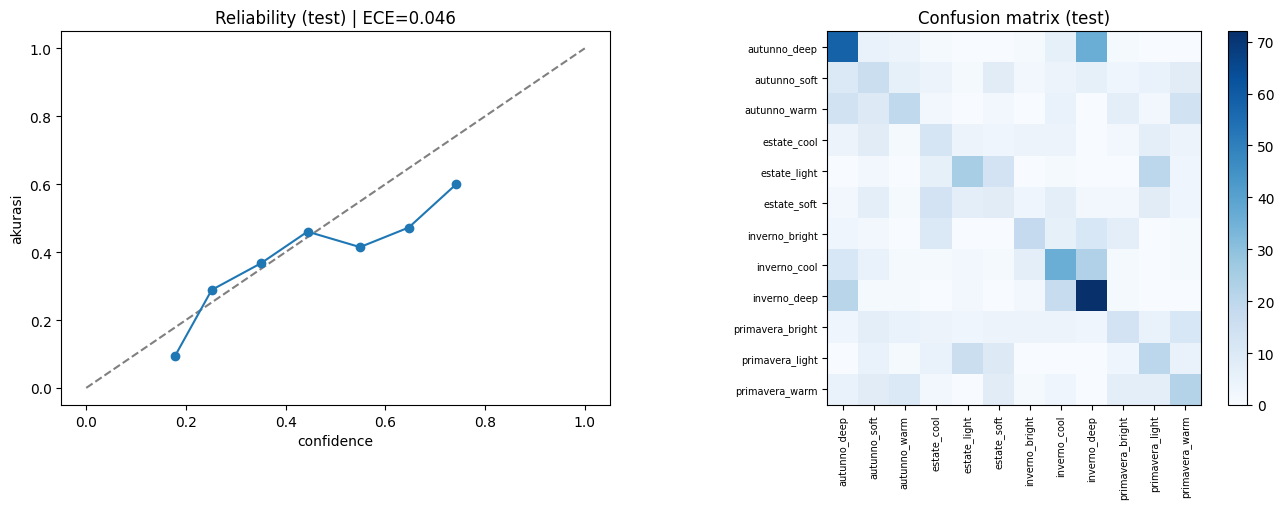

In [22]:
# ============================================================
# 9.2 ANALISIS PER SUB-SEASON DAN CONFUSION
# ============================================================
pred_e, conf_te = p_test.argmax(1), p_test.max(1)
prec, rec, f1c, sup = precision_recall_fscore_support(yte, pred_e, labels=list(range(NUM_CLASSES)), zero_division=0)
pred_h = p_hold.argmax(1)
_, rec_h, _, _ = precision_recall_fscore_support(yho, pred_h, labels=list(range(NUM_CLASSES)), zero_division=0)
per_class_df = pd.DataFrame({"class": class_names, "support_test": sup, "precision_test": prec, "recall_test": rec,
                             "f1_test": f1c, "recall_holdout": rec_h}).sort_values("recall_test").reset_index(drop=True)
display(per_class_df.round(3))
per_class_df.to_csv(RESULT_DIR / "E13_per_subseason.csv", index=False)

cm = confusion_matrix(yte, pred_e, labels=list(range(NUM_CLASSES)))
pairs = [{"actual": idx2class[i], "predicted": idx2class[j], "count": int(cm[i, j]),
          "same_season": bool(season_of[i] == season_of[j])}
         for i in range(NUM_CLASSES) for j in range(NUM_CLASSES) if i != j and cm[i, j] > 0]
if pairs:
    display(pd.DataFrame(pairs).sort_values("count", ascending=False).head(12).reset_index(drop=True))

fig, axes = plt.subplots(1, 2, figsize=(13, 5.2))
edges = np.linspace(0, 1, 11)
xs, ys = [], []
for i in range(10):
    m = (conf_te >= edges[i]) & (conf_te < edges[i + 1] if i < 9 else conf_te <= edges[i + 1])
    if m.sum() >= 5:
        xs.append(conf_te[m].mean()); ys.append((pred_e == yte)[m].mean())
axes[0].plot([0, 1], [0, 1], "--", color="gray"); axes[0].plot(xs, ys, "o-")
axes[0].set_xlabel("confidence"); axes[0].set_ylabel("akurasi"); axes[0].set_title(f"Reliability (test) | ECE={test_m['ece']:.3f}")
im = axes[1].imshow(cm, cmap="Blues")
axes[1].set_xticks(range(NUM_CLASSES)); axes[1].set_yticks(range(NUM_CLASSES))
axes[1].set_xticklabels(class_names, rotation=90, fontsize=7); axes[1].set_yticklabels(class_names, fontsize=7)
axes[1].set_title("Confusion matrix (test)"); plt.colorbar(im, ax=axes[1], fraction=0.046)
plt.tight_layout(); plt.savefig(RESULT_DIR / "E13_test_diagnostics.png", dpi=130); plt.show()

In [23]:
# ============================================================
# 10. SIMPAN ARTEFAK
# ============================================================
artifacts = {
    "experiment_id": EXPERIMENT_ID, "class_names": class_names, "season_of": season_of, "char_of": char_of, "warm_of": warm_of,
    "comp_names": COMP_NAMES, "comp_temps": COMP_T, "ens_weights": ENS_W, "temperature": TEMP,
    "models": COMP_MODEL, "emb_keys": EMB_KEYS, "C": BEST_C, "region_cols": REGION_COLS, "reg_keep": REG_KEEP,
    "color_preps": COLOR_PREPS, "frozen_backbone": FROZEN_HF_ID, "ft_backbone": FT_HF_ID, "parser": PARSER_HF_ID,
    "parse_size": PARSE_SIZE, "cache_size": CACHE_SIZE, "ft_img_size": FT_IMG_SIZE, "mask_used": bool(MASK_OK),
    "ft_ckpts": [f"ft_s{s}_f{k}.pt" for s in FT_SEEDS for k in range(N_FOLDS)],
}
dump(artifacts, RESULT_DIR / "E13_artifacts.joblib")
pd.DataFrame({
    "path": df["resolved_path"].astype(str).to_numpy()[test_rows],
    "true": [idx2class[i] for i in yte], "pred": [idx2class[i] for i in pred_e], "confidence": conf_te,
    "top3": ["|".join(class_names[j] for j in np.argsort(-p_test[i])[:3]) for i in range(len(test_rows))],
}).to_csv(RESULT_DIR / "E13_test_predictions.csv", index=False)
summary = {"experiment_id": EXPERIMENT_ID, "smoke_test": SMOKE_TEST, "comp_names": COMP_NAMES,
           "ens_weights": dict(zip(COMP_NAMES, ENS_W)), "comp_temps": COMP_T, "temperature": TEMP,
           "identity_used": IDENTITY_USED, "n_dev": int(len(train_rows)), "n_holdout": int(len(hold_rows)),
           "holdout_metrics": hold_m, "test_metrics": test_m, "target_acc": TARGET_ACC}
(RESULT_DIR / "E13_summary.json").write_text(json.dumps(summary, indent=2, default=float))
print("Tersimpan di", RESULT_DIR)

Tersimpan di /kaggle/working/E13


In [24]:
# ============================================================
# 11. CATAT HASIL KE modellab_registry
# ============================================================
import modellab_registry

# 0. Kumpulkan metrik official test (ensemble E13) + holdout
_prec, _rec, _, _ = precision_recall_fscore_support(yte, pred_e, labels=list(range(NUM_CLASSES)), average="macro", zero_division=0)
final_metrics = {"accuracy": test_m["acc"], "macro_f1": test_m["macro_f1"], "macro_precision": float(_prec),
                 "macro_recall": float(_rec), "top3": test_m["top3"],
                 "holdout_accuracy": hold_m["acc"], "holdout_macro_f1": hold_m["macro_f1"]}
print({k: round(float(v), 4) for k, v in final_metrics.items()})

# 1. Ekstrak hasil evaluasi yang sudah dihitung oleh notebook di sel sebelumnya
accuracy = final_metrics["accuracy"]
f1_score = final_metrics["macro_f1"]
precision = final_metrics["macro_precision"]
recall = final_metrics["macro_recall"]

# 2. Panggil fungsi auto-log, sertakan globals() dan panggil variabel konfigurasi master
modellab_registry.auto_log_experiment(
    env_globals=globals(),
    topic="topic-a",
    model="DINOv3 ViT-B/16 Fusion",
    objective="E13: fusion DINOv3 ViT-B + Lab per region, logit hierarkis, label smoothing hierarkis, EMA, grup per orang diperbaiki",
    dataset="deep_armocromia",
    owner="Fatih Itsbatul Haq"
)

{'accuracy': 0.3498, 'macro_f1': 0.3205, 'macro_precision': 0.3285, 'macro_recall': 0.3204, 'top3': 0.716, 'holdout_accuracy': 0.3333, 'holdout_macro_f1': 0.315}
===REGISTRY_PAYLOAD_START===
{"topic": "topic-a", "model": "DINOv3 ViT-B/16 Fusion", "objective": "E13: fusion DINOv3 ViT-B + Lab per region, logit hierarkis, label smoothing hierarkis, EMA, grup per orang diperbaiki", "dataset": "deep_armocromia", "owner": "Fatih Itsbatul Haq", "metrics": {"accuracy": 0.34978070175438597, "f1": 0.3205261400240745, "precision": 0.328503195422232, "recall": 0.3204497871040814}}
===REGISTRY_PAYLOAD_END===
